<a href="https://colab.research.google.com/github/VRaca-Code/P2PCreditRiskValidation/blob/main/P2PCreditRiskValidation_Clean_5_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Performance, Complexity and Explanation Stability in P2P Credit-Risk Models

**What this notebook does.** It is a thin driver: all logic lives in `src/`, and each section below
calls one module and shows its output. In order it (1) sets up the configuration and a chronological
train / test split, (2) audits the data cleaning, (3) fits every model for every seed, (4) tests H1
(are models performance-equivalent?), (5) tests H2 and H3 (do explanations differ beyond seed noise?),
(6) checks calibration, (7) runs drift, stress and backtest checks, (8) compares runs with and without
the lender's own `int_rate` / `sub_grade`, and (9) builds the scorecard and trade-off plots.

Set `USE_SYNTHETIC = False` and place the LendingClub CSV in `data/raw/` (see `data/README.md`) for the
real analysis. With synthetic data the numbers only prove the pipeline runs.

**Hypotheses.** H1: model pairs are performance-equivalent (PR-AUC, TOST) or not. H2: explanations
shift between models by more than seed-to-seed variation. H3: some pair is equivalent in performance
but explained differently.

> **Five-model version.** This notebook selects Logistic Regression, Random Forest, XGBoost, DNN and KAN in the original configuration cell. Run cells from top to bottom to regenerate consistent tables and figures. Synthetic data is a pipeline demonstration, not real-world validation.


In [1]:
import os
import sys

REPO = "/content/P2PCreditRiskValidation"

if not os.path.isdir(REPO):
    !git clone https://github.com/VRaca-Code/P2PCreditRiskValidation.git

os.chdir(REPO)
sys.path.insert(0, REPO)

print("Repository loaded:", os.getcwd())

Cloning into 'P2PCreditRiskValidation'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 78 (delta 12), reused 69 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (78/78), 2.80 MiB | 4.90 MiB/s, done.
Resolving deltas: 100% (12/12), done.
Repository loaded: /content/P2PCreditRiskValidation


### 0. Setup
Imports the package, silences warnings and chooses synthetic or real data.

In [2]:
import sys, warnings
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import ExperimentConfig, USECOLS, ALL_MODELS
from src.experiments import (load_frame, load_splits, run_seed_grid, run_hypothesis_tests, summarise,
                             save_tables, run_feature_set_comparison)
from src.models import available_models

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

USE_SYNTHETIC = True        # True = generated data (pipeline check only); False = real LendingClub CSV
COMPARE_FEATURE_SETS = True # section 7 re-runs everything twice; set False to skip on large real runs
print("Models available in this environment:", available_models())

Models available in this environment: ['Logistic Regression', 'Random Forest', 'XGBoost', 'DNN', 'KAN']


### 1. Configuration and chronological split
Builds the settings object, then cleans the data and splits it by origination date (train = earlier months, test = latest months).

In [3]:
cfg = replace(ExperimentConfig(), models=ALL_MODELS)
if USE_SYNTHETIC:
    cfg = replace(cfg, seeds=tuple(range(4)), seed_train_size=3_000, explain_size=400,
                  n_boot=100, n_boot_explain=300, top_k=5,
                  output_dir=ROOT / "outputs" / "tables" / "synthetic_demo")

splits = load_splits(cfg, synthetic=USE_SYNTHETIC)
X_train, y_train, X_test, y_test = splits
print(f"lender score dropped: {cfg.drop_lender_assigned}")
print(f"train {len(X_train):,} rows, default rate {y_train.mean():.2%}")
print(f"test  {len(X_test):,} rows, default rate {y_test.mean():.2%}  (later origination months)")

lender score dropped: True
train 5,841 rows, default rate 14.35%
test  1,601 rows, default rate 17.18%  (later origination months)


### 2. Data-quality audit
Shows how many loans survive each cleaning step, which loan statuses were dropped, the default rate by issue year (a sharp fall in the latest years means right-censoring) and the most-missing features. See `docs/data_cleaning.md` for the reasons.

In [4]:
from src.data_quality import data_quality_report
from src.synthetic import make_synthetic_lendingclub

raw = (make_synthetic_lendingclub(8_000, seed=0) if USE_SYNTHETIC
       else pd.read_csv(cfg.csv_path, usecols=USECOLS, low_memory=False))
report = data_quality_report(raw, cfg, verbose=False)
display(report["attrition"])
display(report["status_breakdown"])
display(report["default_rate_by_year"])
display(report["missingness"].head(10))

,Step,Rows,Rows_removed,Default_rate,Note
0,Raw rows,8000,NaN,NaN,as loaded from the CSV
1,Resolved loans only,7442,558.0,0.149557,Fully Paid / Charged Off / Default kept; Curre...
2,After stratified sample,7442,0.0,0.149557,sample_size=200000; default rate preserved
3,Valid issue date,7442,0.0,0.149557,0 rows with unparseable issue_d removed
4,Issued <= 2016,7442,0.0,0.149557,later vintages are right-censored (most have n...
5,Training set (earlier months),5841,NaN,0.143469,fits models and preprocessors
6,Test set (latest months),1601,NaN,0.171768,never used for fitting


,Raw_status,Rows,Kept,Encoded_as,Share
0,Fully Paid,6329,True,0.0,0.791125
1,Charged Off,1113,True,1.0,0.139125
2,Current,474,False,NaN,0.059250
3,Late (31-120 days),84,False,NaN,0.010500


,Issue_year,Loans,Default_rate
0,2012,1527,0.134250
1,2013,1451,0.135768
2,2014,1524,0.149606
3,2015,1462,0.159371
4,2016,1478,0.169147


,dtype,missing_count,missing_rate,n_unique
mort_acc,float64,498,0.085259,6
emp_length,float64,281,0.048108,6
revol_util,float64,57,0.009759,5704
installment,float64,0,0.000000,5841
term,float64,0,0.000000,2
loan_amnt,float64,0,0.000000,69
annual_inc,float64,0,0.000000,5841
home_ownership,object,0,0.000000,4
addr_state,object,0,0.000000,10
verification_status,object,0,0.000000,3


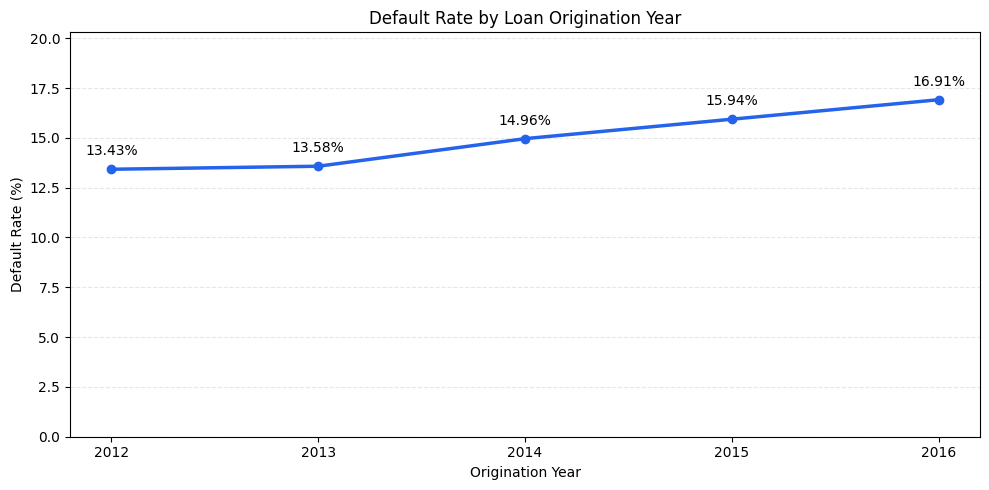

,Issue_year,Loans,Default_rate
0,2012,1527,0.134250
1,2013,1451,0.135768
2,2014,1524,0.149606
3,2015,1462,0.159371
4,2016,1478,0.169147


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def plot_default_rate_by_year(
    df,
    date_col="issue_d",
    status_col="loan_status",
    save_path="outputs/figures/default_rate_by_year.png"
):
    # Keep only resolved loan outcomes
    data = df.loc[
        df[status_col].isin(
            ["Fully Paid", "Charged Off", "Default"]
        ),
        [date_col, status_col]
    ].copy()

    # Convert origination dates
    data[date_col] = pd.to_datetime(
        data[date_col], errors="coerce"
    )

    # Remove invalid dates and apply study cutoff
    data = data.dropna(subset=[date_col])
    data = data[data[date_col].dt.year <= 2016]

    # Binary outcome: 1 = default, 0 = fully paid
    data["default_target"] = (
        data[status_col].isin(["Charged Off", "Default"])
    ).astype(int)

    # Aggregate automatically by origination year
    yearly = (
        data.groupby(data[date_col].dt.year)
        .agg(
            Loans=("default_target", "size"),
            Default_rate=("default_target", "mean")
        )
        .reset_index()
        .rename(columns={date_col: "Issue_year"})
    )

    if yearly.empty:
        raise ValueError("No eligible resolved loans found.")

    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        yearly["Issue_year"],
        yearly["Default_rate"] * 100,
        marker="o",
        linewidth=2.5,
        color="#2563EB"
    )

    for _, row in yearly.iterrows():
        ax.annotate(
            f"{row['Default_rate']:.2%}",
            (row["Issue_year"], row["Default_rate"] * 100),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

    ax.set_title("Default Rate by Loan Origination Year")
    ax.set_xlabel("Origination Year")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xticks(yearly["Issue_year"])
    ax.set_ylim(0, max(5, yearly["Default_rate"].max() * 120))
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()

    # Save figure
    path = Path(save_path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    return yearly


# RUN THE FUNCTION ON YOUR ACTUAL DATAFRAME
yearly_summary = plot_default_rate_by_year(raw)

display(yearly_summary)


### 2b. Data-cleaning figures and exploratory analysis of the portfolio
First draws the cleaning figures (loans left after each step, loan statuses kept vs dropped, feature coverage, censoring by year). Then describes who borrows and where defaults concentrate before any model is fitted: default rate by group with 95% intervals, tests reported with effect sizes, a hand-made risk rule checked against real defaults, interest charged vs defaults realised, and whether missingness is itself a signal. It also shows how much the label definition alone changes the default rate. Methods come from public LendingClub and Bondora notebooks (see `docs/eda.md`).

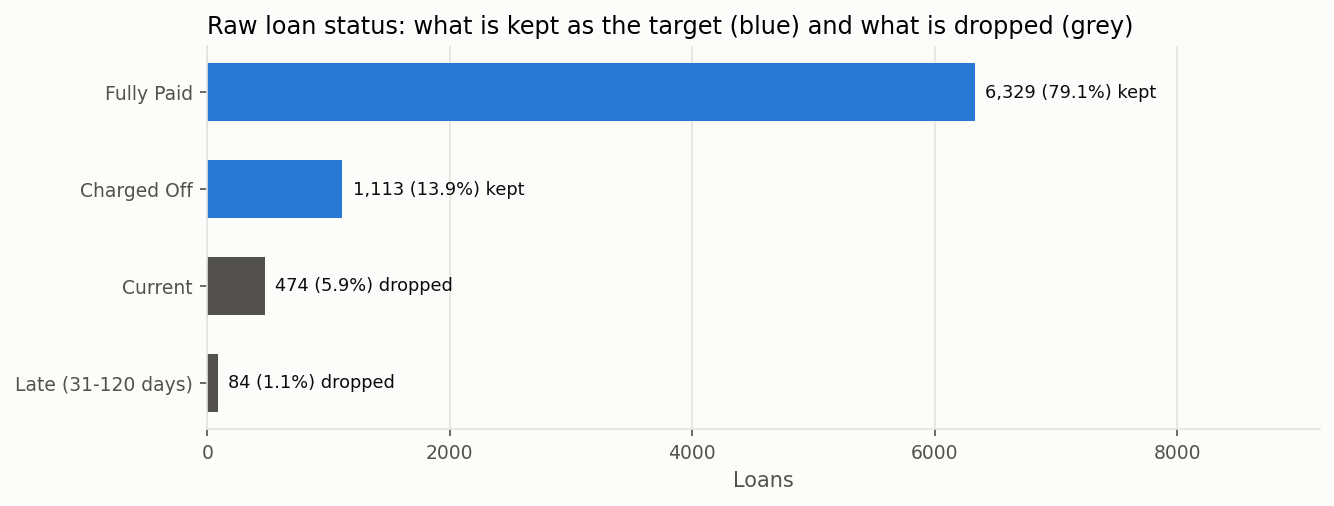

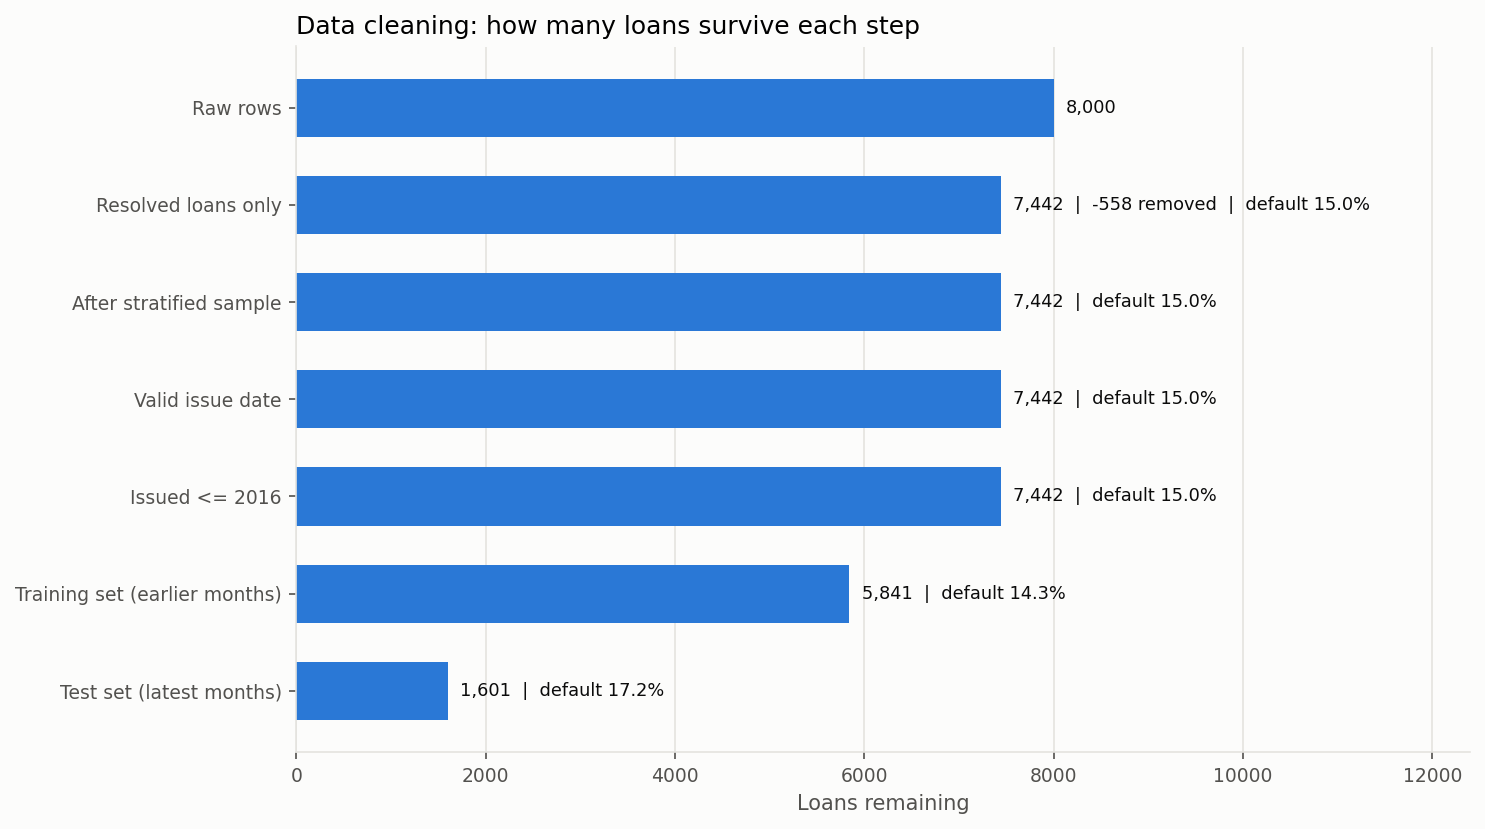

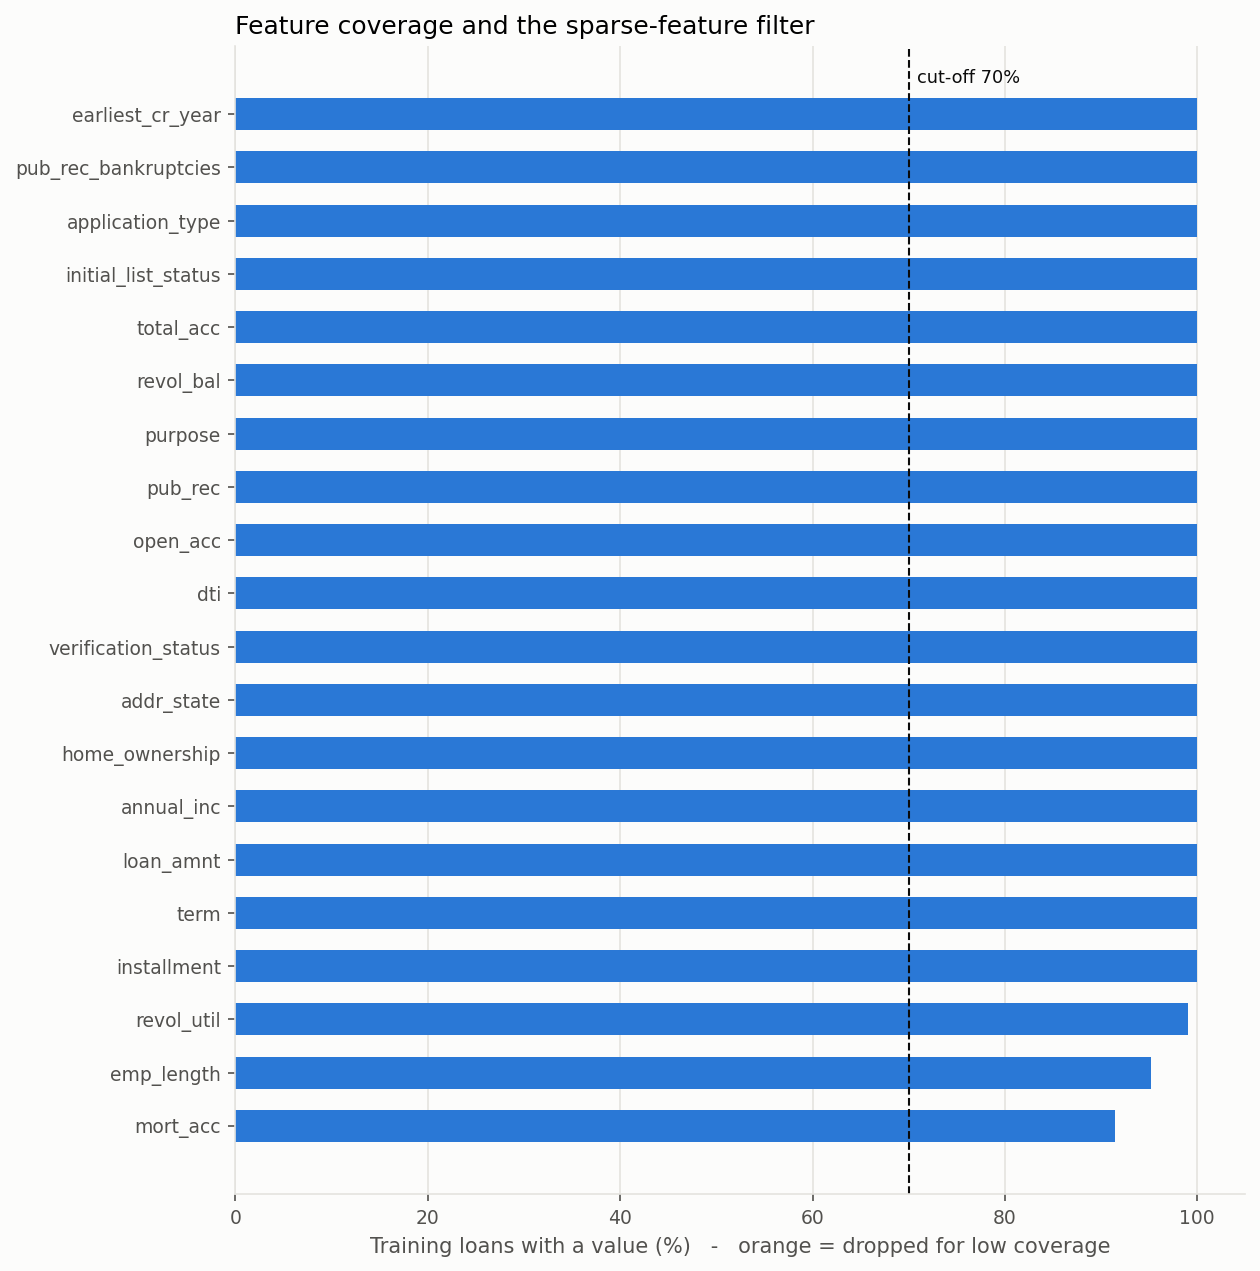

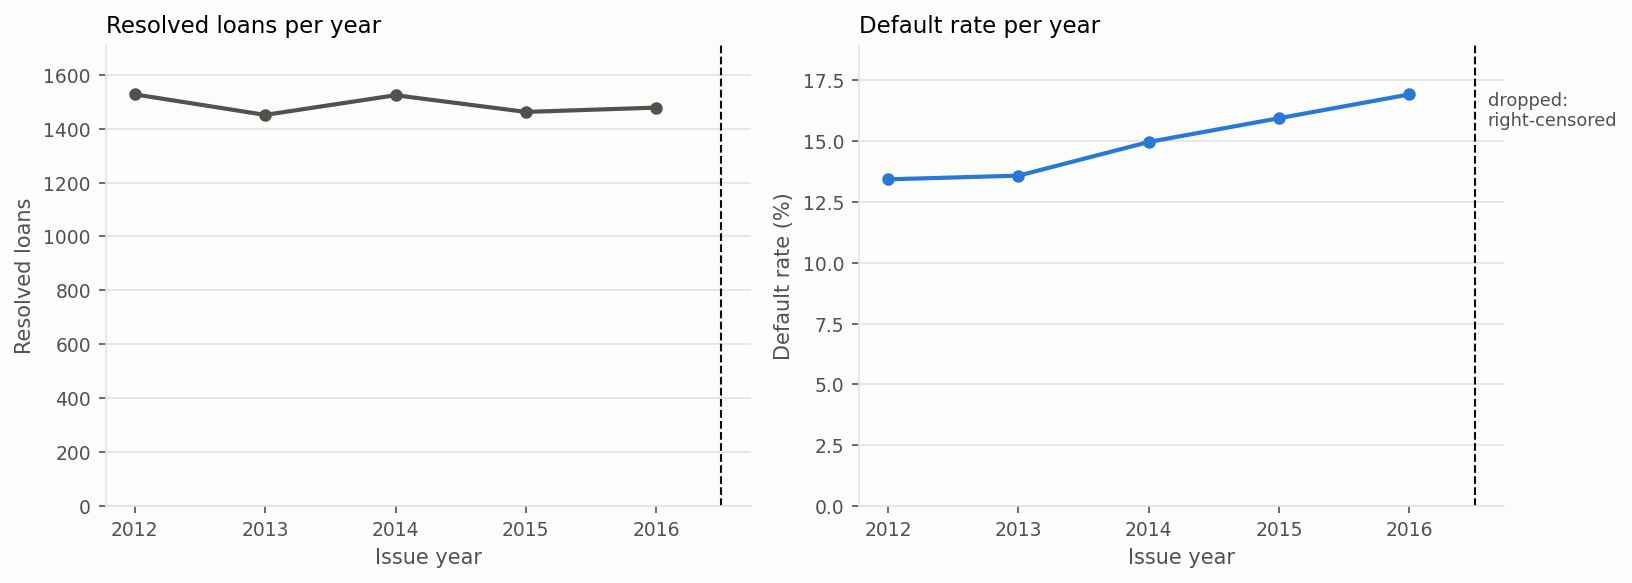


=== label_definitions ===


,Definition,Loans,Default_rate,Rule,Unresolved_loans_in_sample
0,This repo: resolved loans only,7442,0.150,Fully Paid = 0; Charged Off / Default = 1; eve...,0
1,"Notebook style: all loans, unresolved counted",8000,0.150,Current = good; Late / Grace Period / Charged ...,558
2,"Notebook style, Current excluded",7526,0.159,late loans still labelled bad before they resolve,84



=== hypothesis_tests ===


,Test,Variable,Statistic,p_value,Effect_size,Effect_measure,Effect_label,Mean_defaulted,Mean_paid
0,Welch t (defaulted - paid),int_rate,18.256,0.000,0.607,Cohen's d,medium,14.700,13.223
1,Welch t (defaulted - paid),loan_amnt,0.297,0.767,0.010,Cohen's d,negligible,17970.350,17872.413
2,Welch t (defaulted - paid),dti,8.546,0.000,0.281,Cohen's d,small,19.631,17.594
3,Welch t (defaulted - paid),annual_inc,-11.700,0.000,-0.323,Cohen's d,small,57760.649,70314.197
4,Welch t (defaulted - paid),revol_util,10.143,0.000,0.329,Cohen's d,small,56.460,49.184
5,Welch t (defaulted - paid),fico_score,-16.797,0.000,-0.496,Cohen's d,small,690.877,707.108
6,Chi-square (default vs group),term_months,39.014,0.000,0.072,Cramer's V,negligible,NaN,NaN
7,Chi-square (default vs group),purpose,8.929,0.063,0.035,Cramer's V,negligible,NaN,NaN
8,Chi-square (default vs group),grade,359.795,0.000,0.220,Cramer's V,small,NaN,NaN
9,Chi-square (default vs group),home_ownership,8.655,0.034,0.034,Cramer's V,negligible,NaN,NaN



=== risk_rule_validation ===


,Rule,Flagged_share,Default_rate_flagged,Default_rate_not_flagged,Lift,Precision,Recall,AUC_of_flag,Base_default_rate
0,Loan > 35% of income AND employed <= 1y,0.059,0.165,0.149,1.104,0.165,0.065,0.504,0.15
1,Loan > 35% of income,0.381,0.181,0.130,1.209,0.181,0.460,0.547,0.15
2,Employed <= 1y,0.164,0.130,0.153,0.868,0.130,0.142,0.487,0.15
3,Instalment burden > 25% of income,0.120,0.198,0.143,1.325,0.198,0.159,0.523,0.15


... (2 outputs left out)


=== missingness_informativeness ===


,Feature,Missing_share,Default_rate_missing,Default_rate_observed,Gap_pct_points,Missing_ci95_low,Missing_ci95_high
0,emp_title,0.200,0.172,0.144,2.839,0.154,0.192
1,mort_acc,0.084,0.135,0.151,-1.631,0.110,0.164
2,revol_util,0.010,0.141,0.150,-0.880,0.078,0.240
3,title,0.334,0.146,0.151,-0.505,0.133,0.161
4,emp_length,0.047,0.151,0.150,0.106,0.117,0.192



=== outlier_summary ===


,Feature,Outside_1.5_IQR_share,Above_p99.9_share,Max,Median,Max_over_median,Skewness
0,revol_bal,0.077,0.001,702044.580,10898.322,64.418,7.334
1,annual_inc,0.035,0.001,667504.606,59847.487,11.153,2.347
2,int_rate,0.008,0.001,23.439,13.400,1.749,0.019
3,revol_util,0.004,0.001,120.000,50.263,2.387,0.082
4,fico_score,0.003,0.001,847.000,702.000,1.207,0.570
5,dti,0.003,0.001,45.000,17.827,2.524,0.066
6,installment,0.000,0.001,1274.816,535.741,2.380,0.192
7,loan_amnt,0.000,0.000,35000.000,17500.000,2.000,0.009
8,open_acc,0.000,0.000,29.000,16.000,1.812,-0.002
9,total_acc,0.000,0.000,59.000,31.000,1.903,0.007


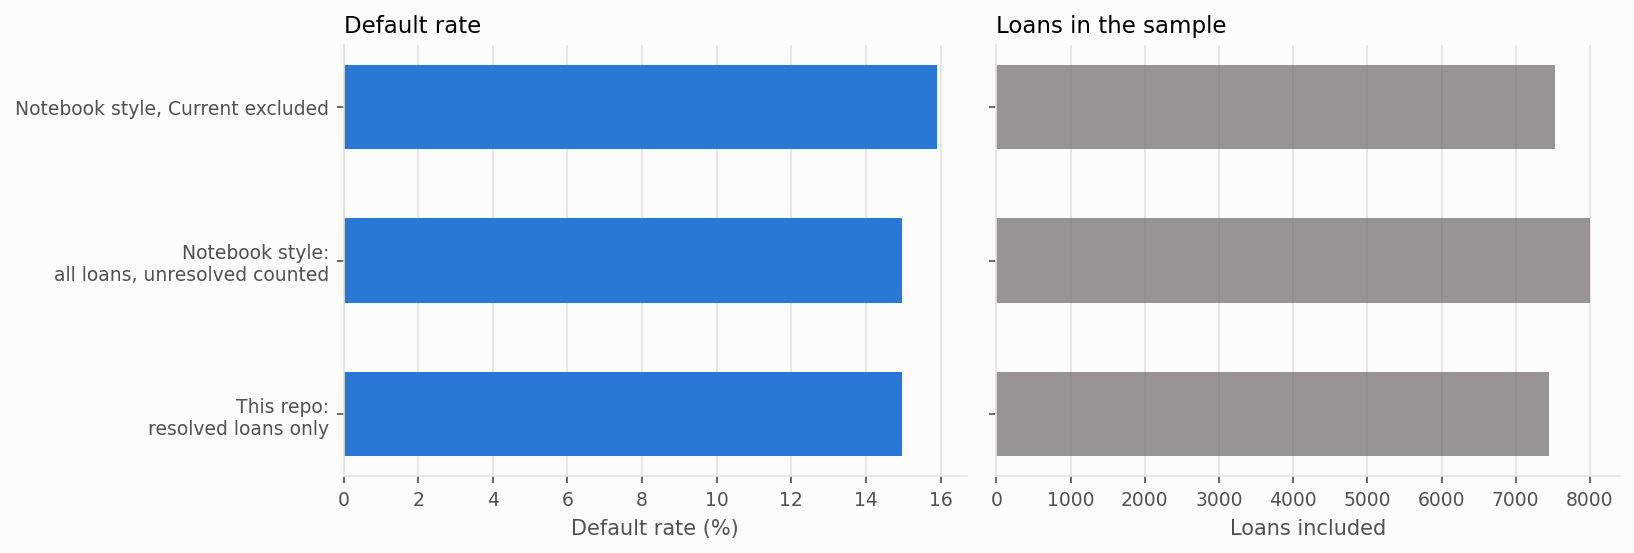

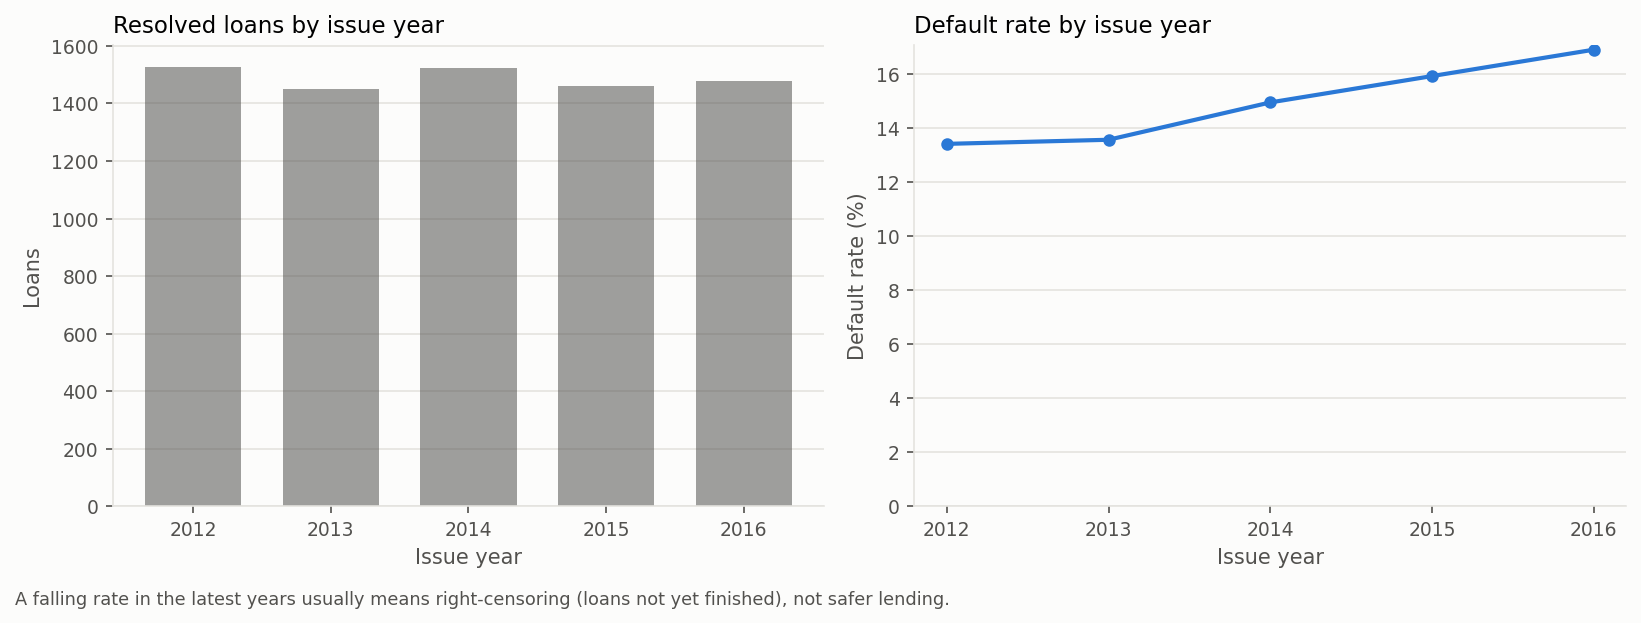

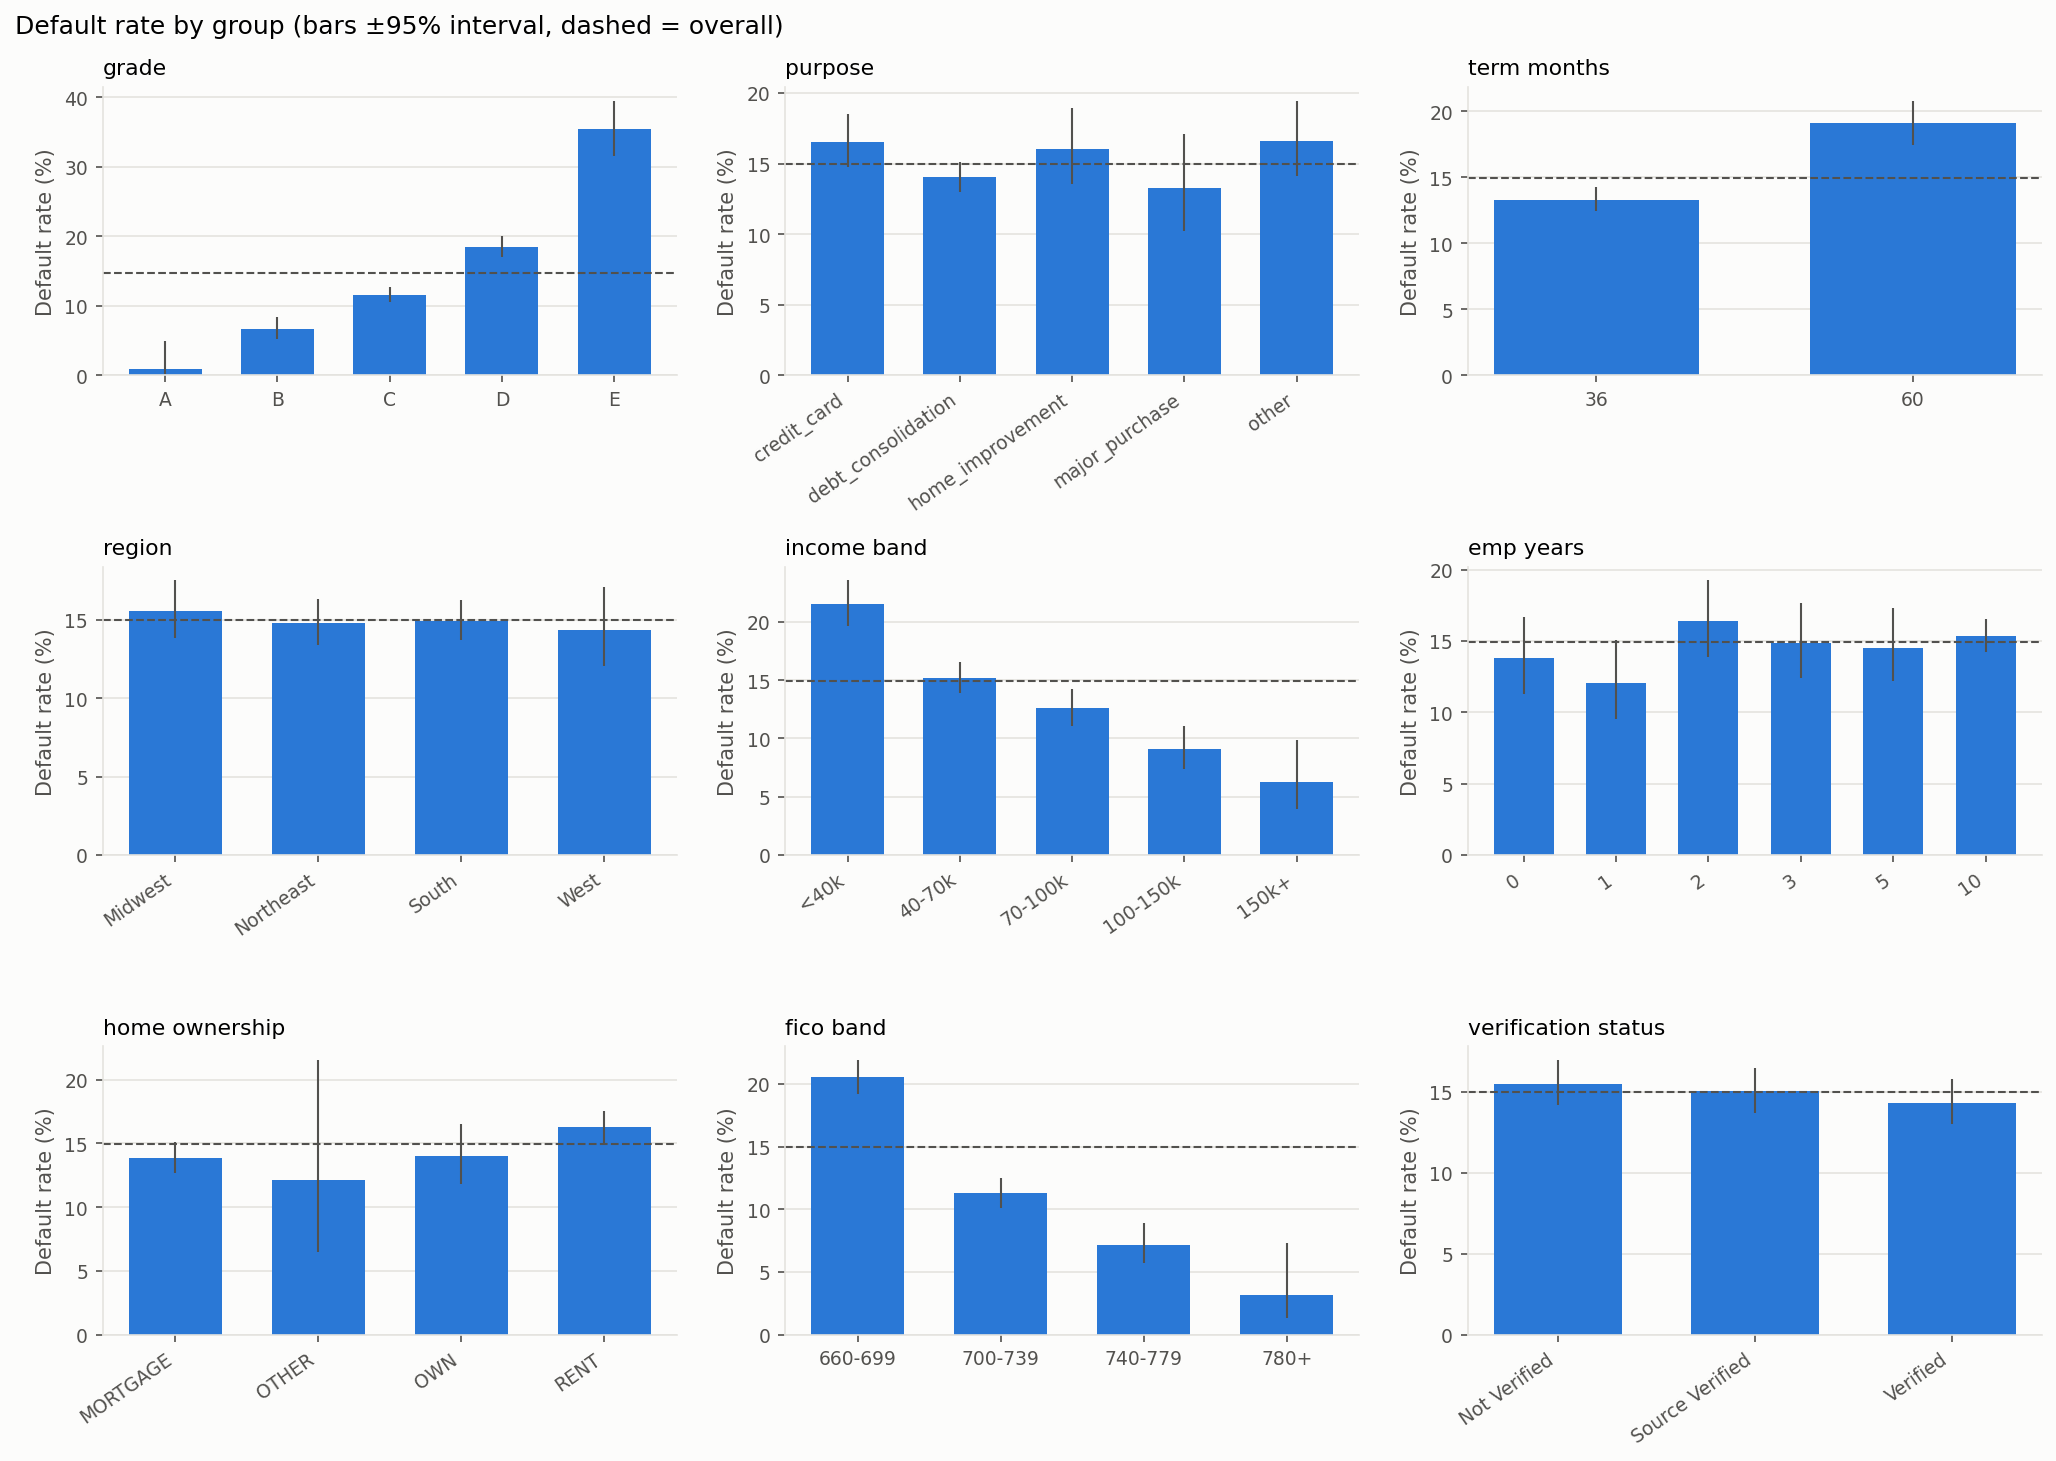

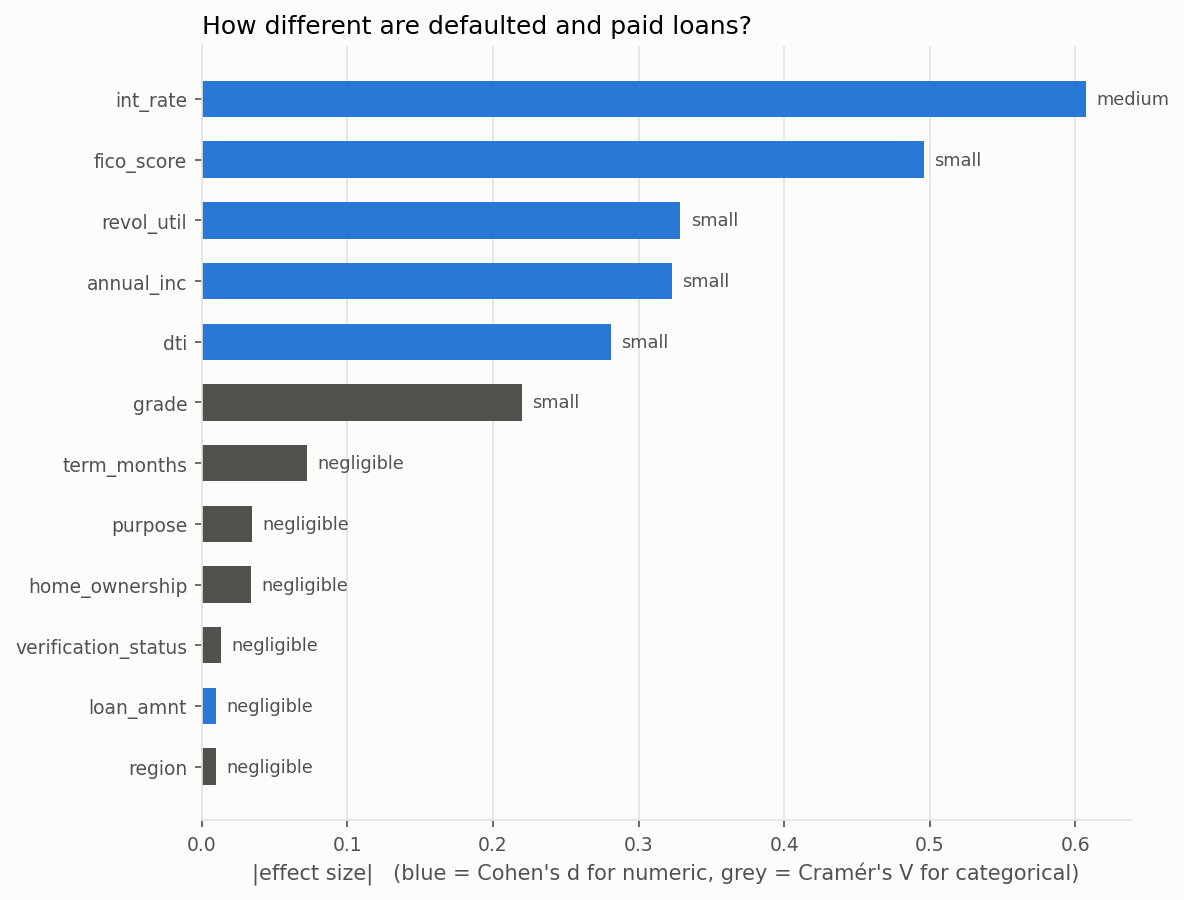

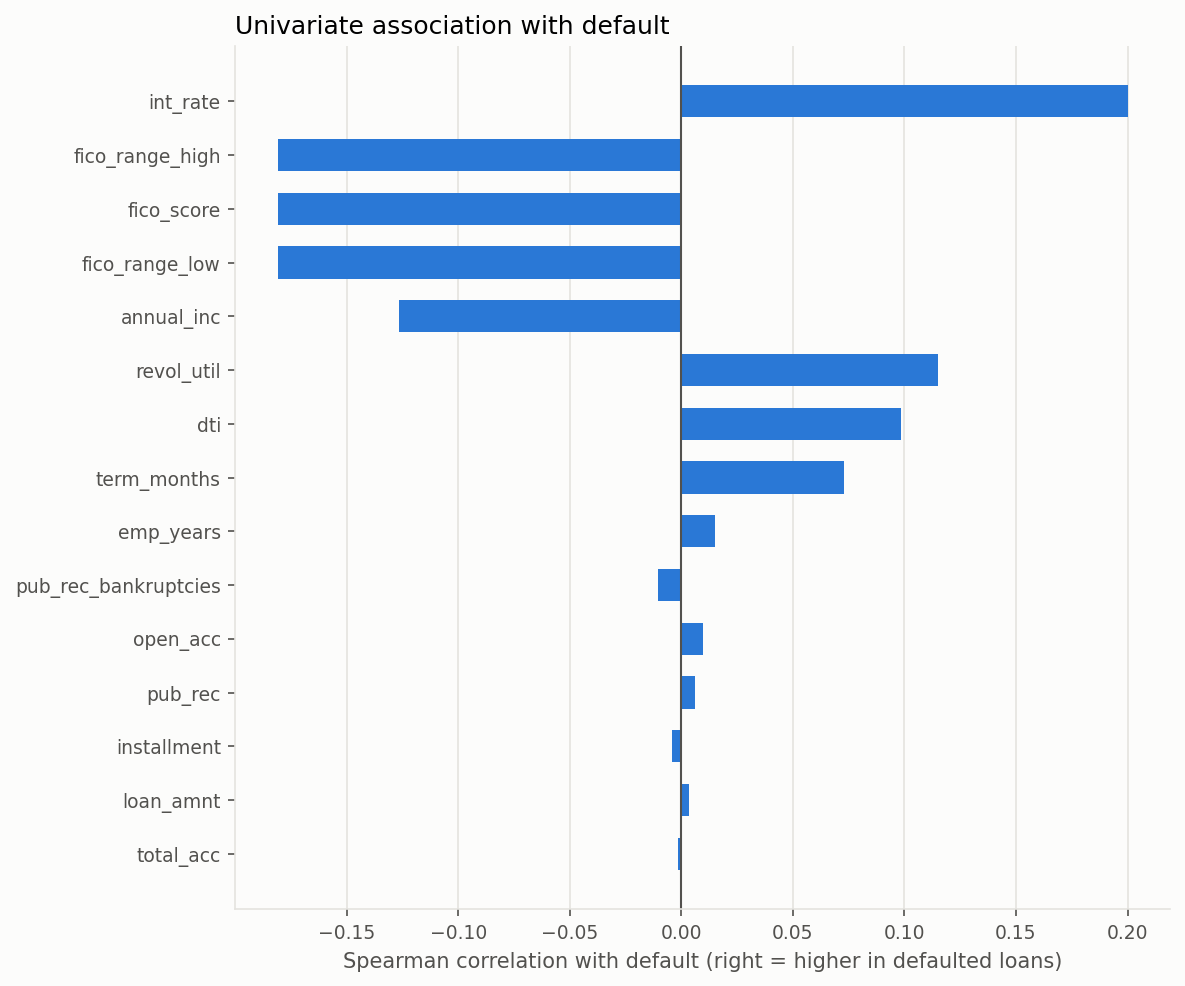

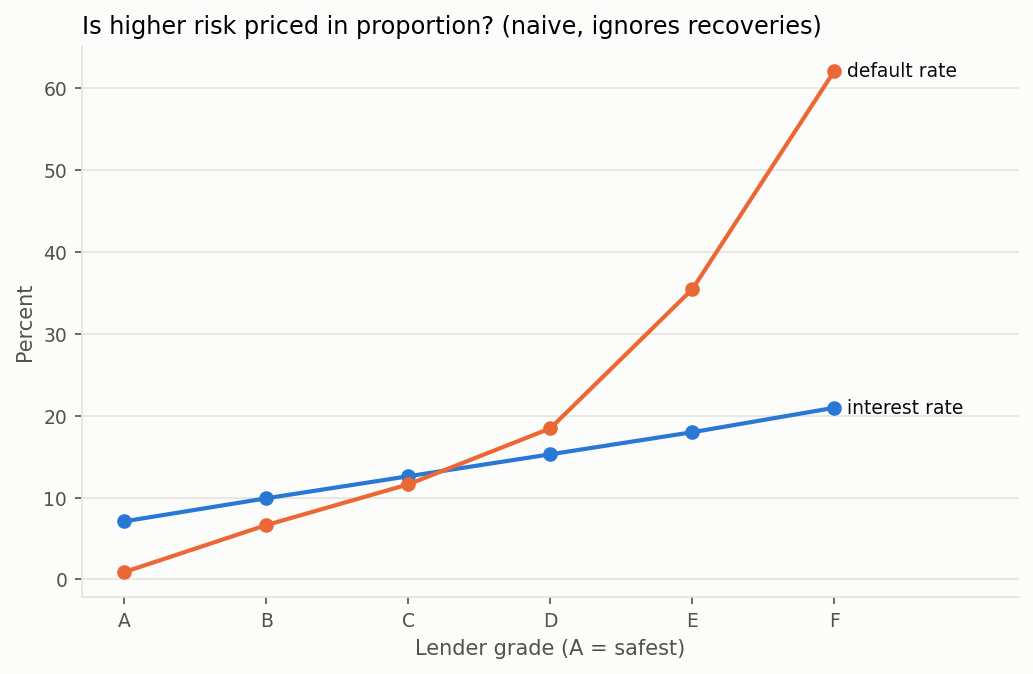

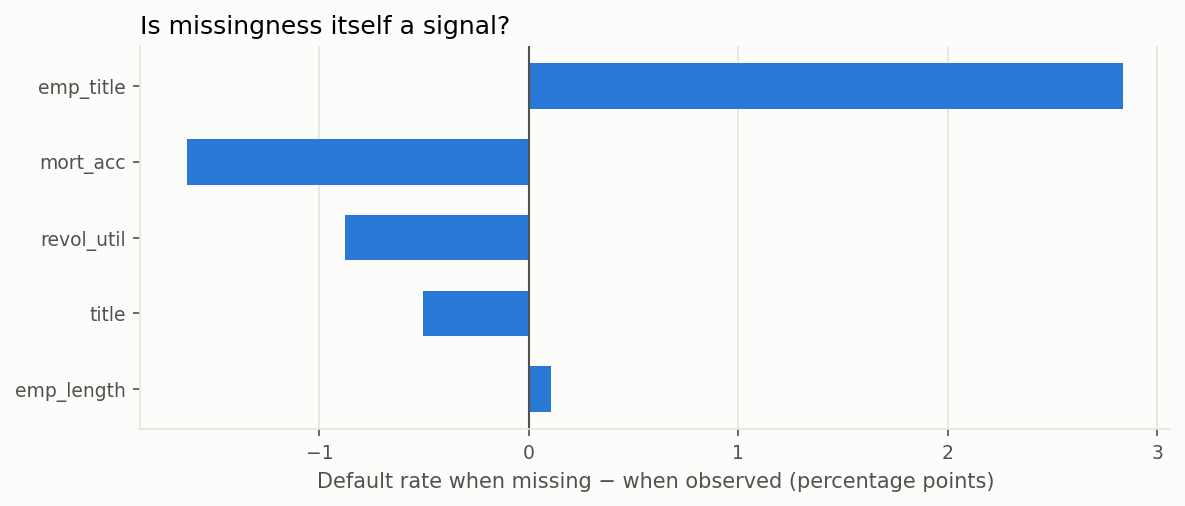

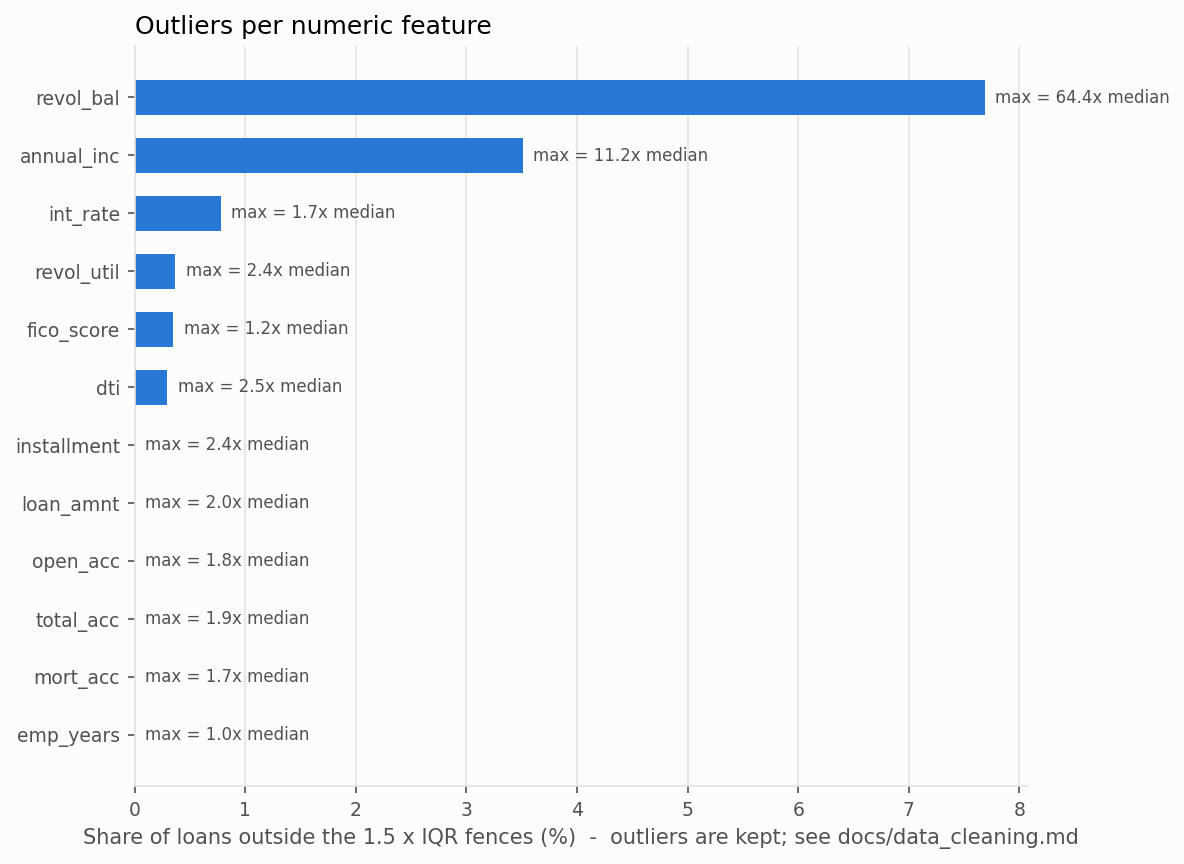

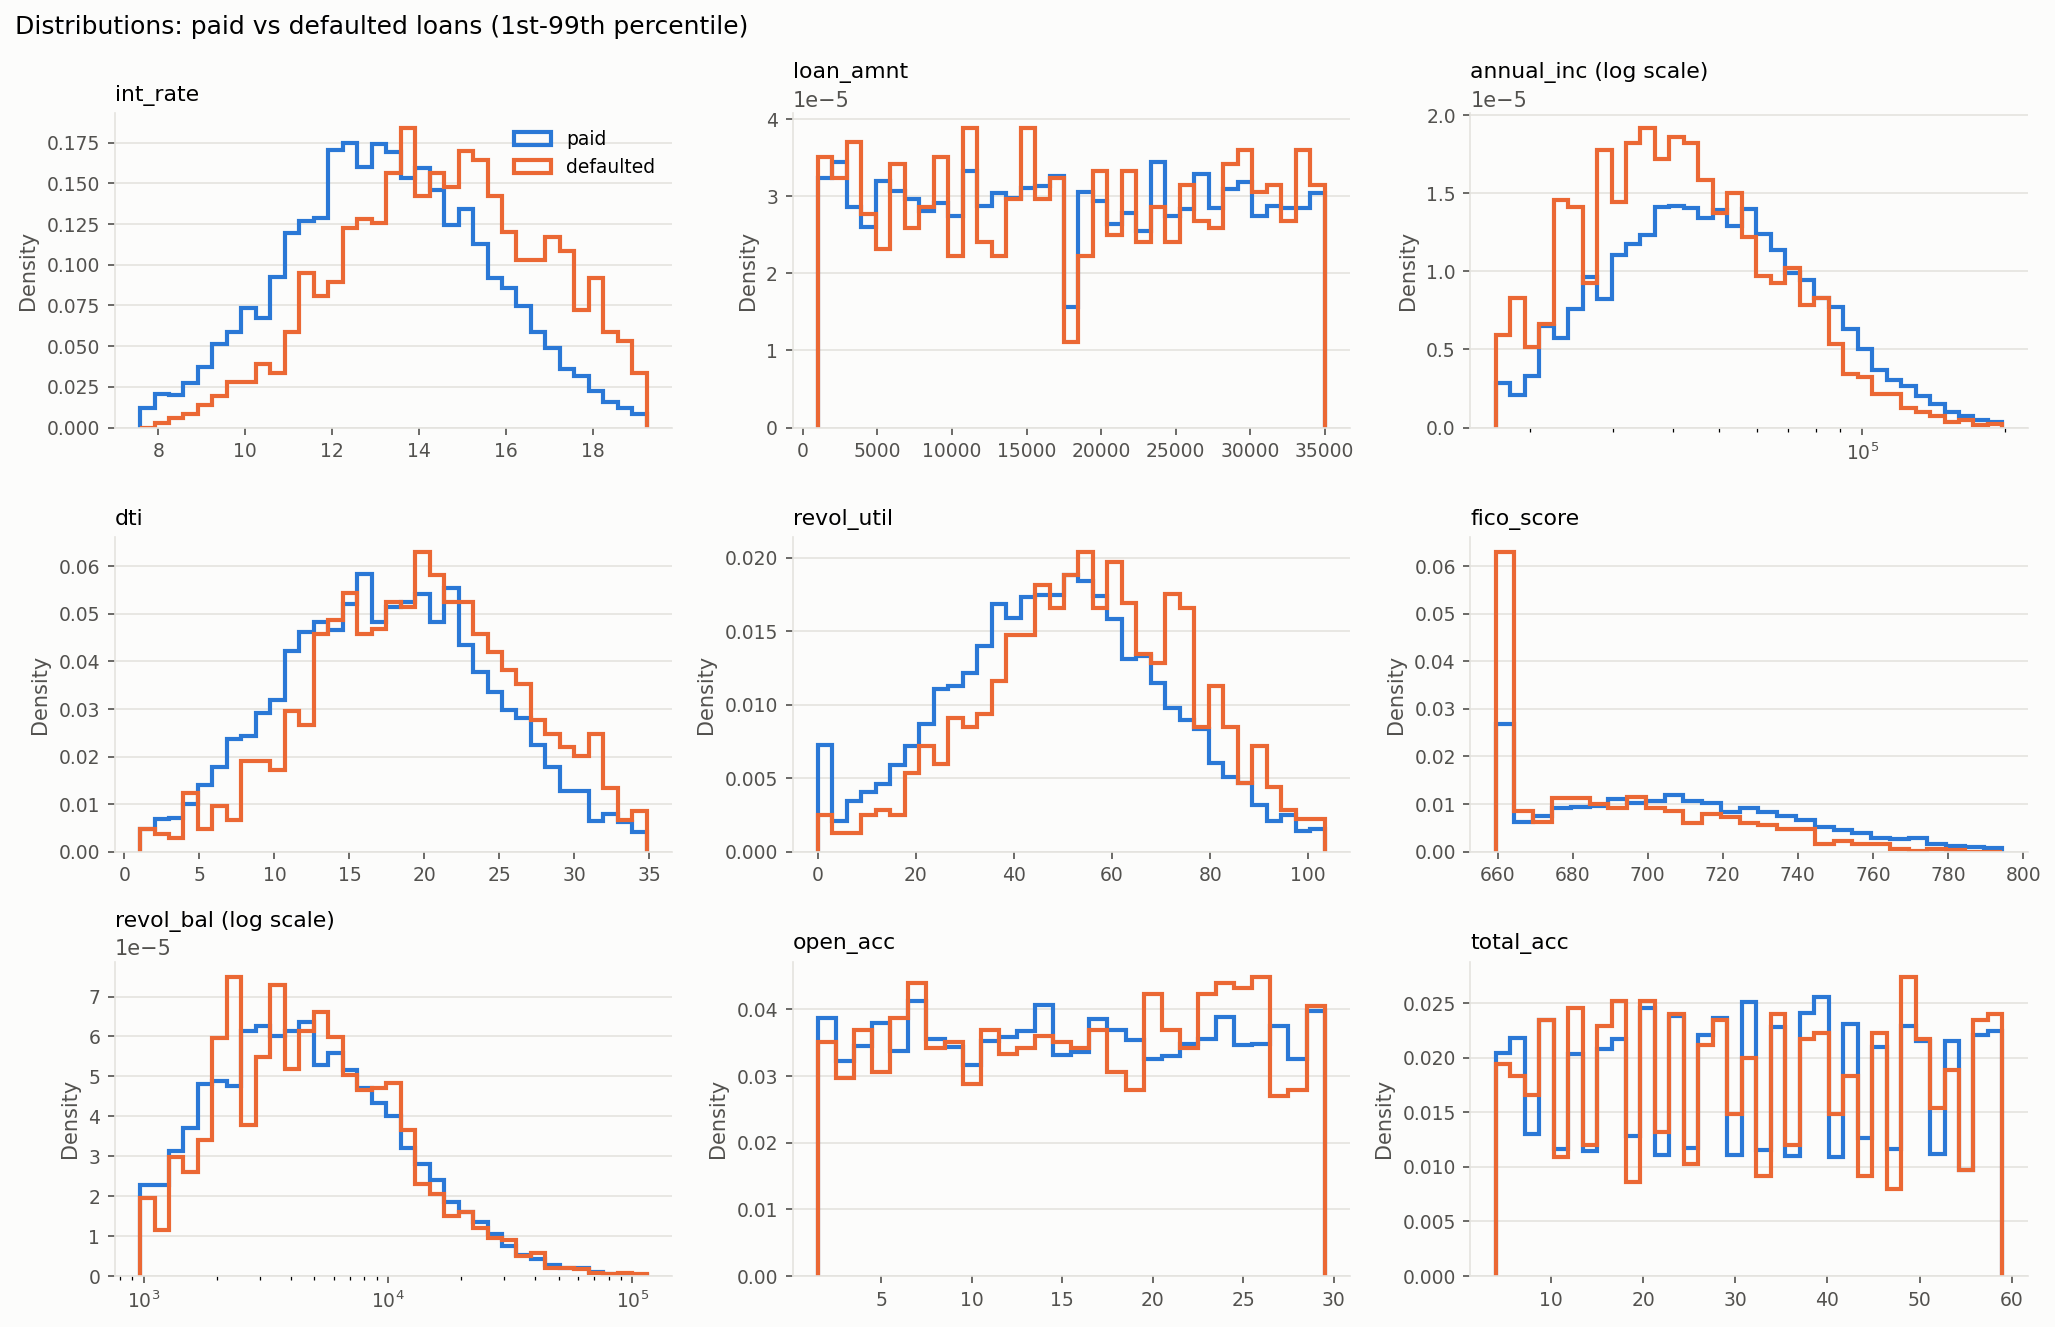

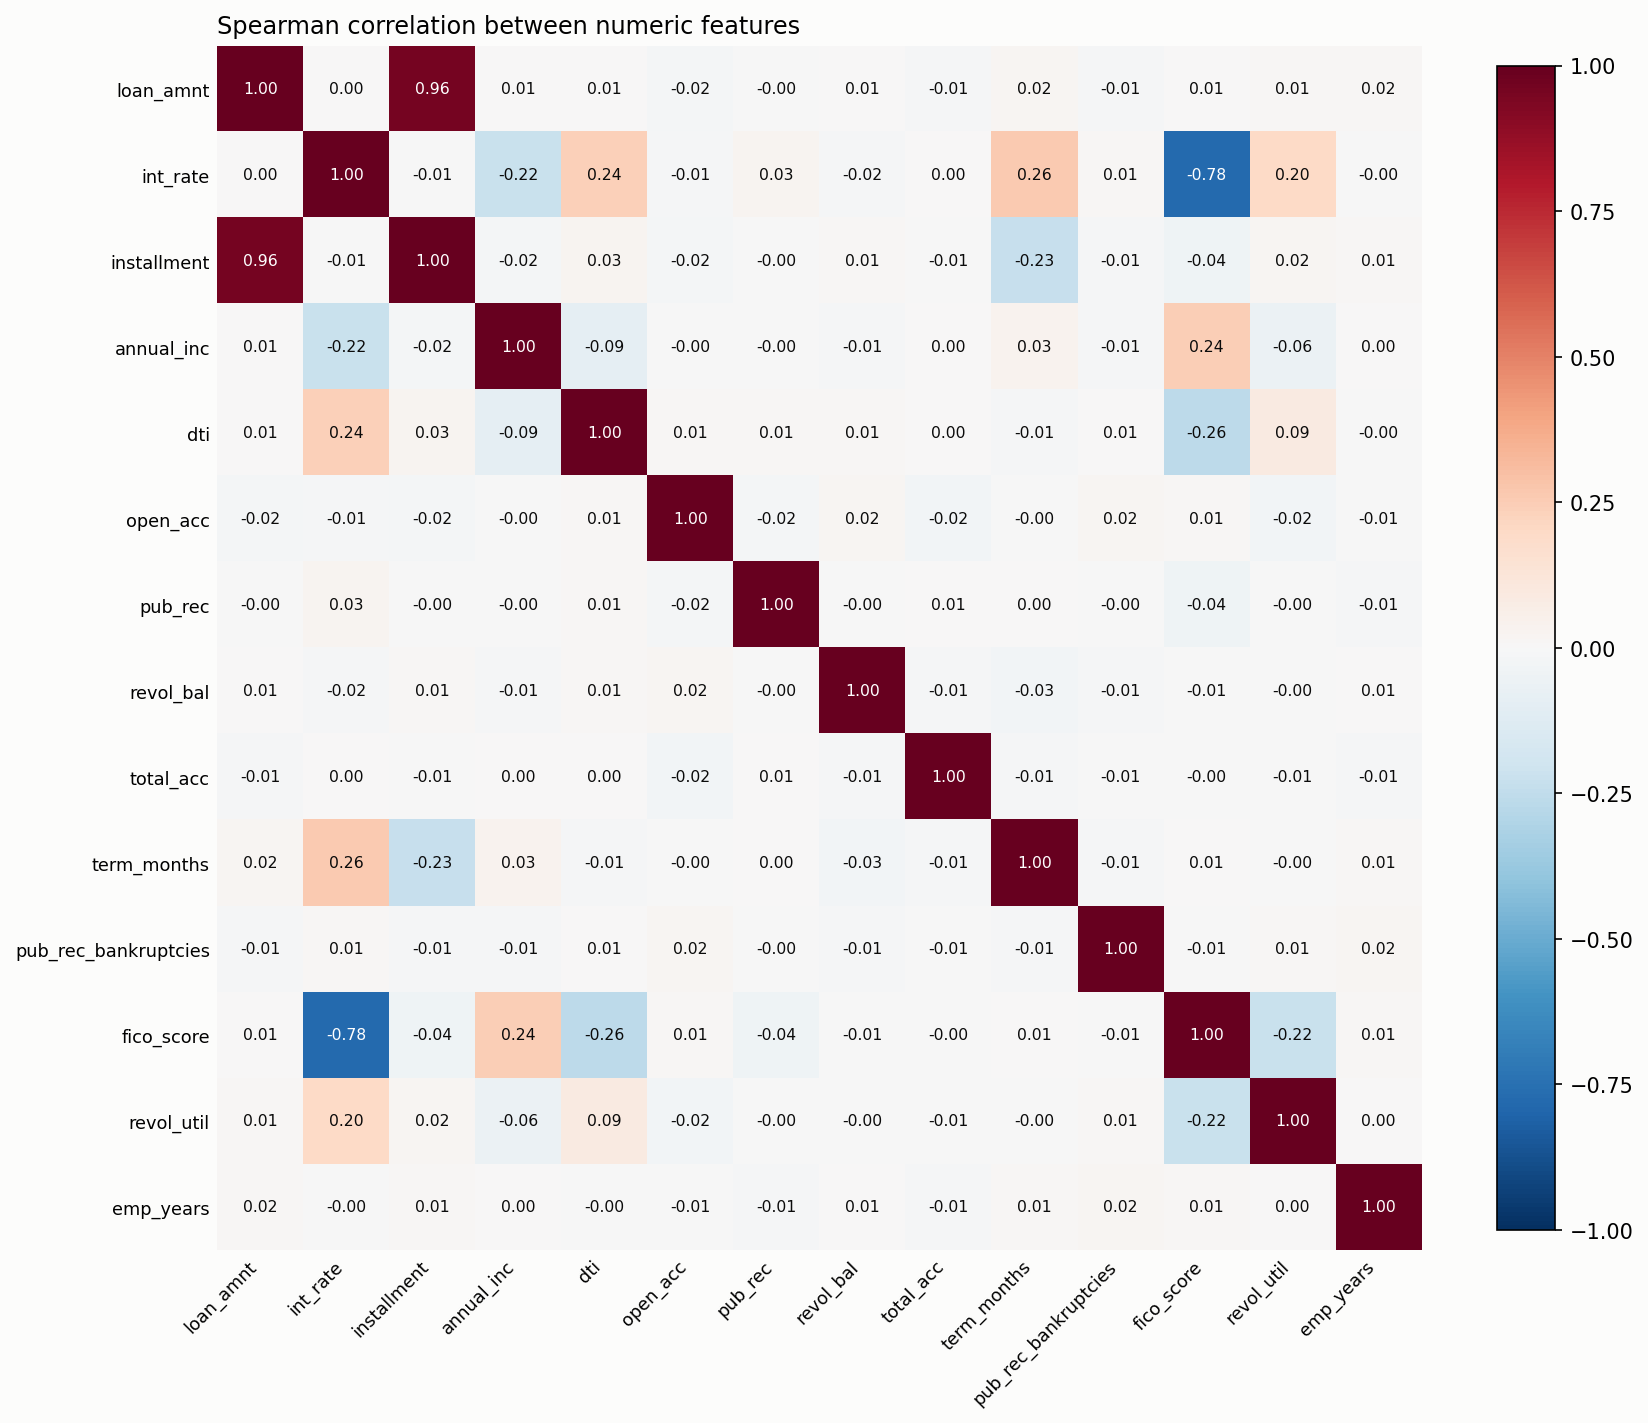

In [6]:
from src.eda import eda_report
from src.visualization import save_eda_figures

from src.data_quality import data_quality_report
from src.visualization import save_data_quality_figures
dq = data_quality_report(raw, cfg, verbose=False)
dq_paths = save_data_quality_figures(dq, ROOT / "outputs" / "figures" / "data_quality", cfg.max_issue_year, cfg.min_feature_coverage)
from IPython.display import Image as _Img
for p in dq_paths:
    display(_Img(filename=str(p), width=800))

eda = eda_report(raw, cfg, verbose=False)
for name in ("label_definitions", "hypothesis_tests", "risk_rule_validation", "pricing_vs_realised_risk", "missingness_informativeness", "outlier_summary"):
    print(f"\n=== {name} ===")
    display(eda[name].round(3))
eda_paths = save_eda_figures(eda, ROOT / "outputs" / "figures" / "eda")
from IPython.display import Image
for p in eda_paths:
    display(Image(filename=str(p), width=800))

### 3. Seed grid
Fits every model for every seed on a different training subsample, scores the same test rows and computes one global importance vector per fit. Then summarises mean performance, calibration, generalization gap and explanation stability per model, and the structural size of each model.

In [7]:
grid = run_seed_grid(splits, cfg, verbose=False)
summary = summarise(grid)
display(summary.round(4))
display(grid["complexity"])

,roc_auc,pr_auc,brier,ece,generalization_gap,seed_std_pr_auc,explanation_stability
Model,,,,,,,
Logistic Regression,0.6463,0.2791,0.1372,0.0315,0.0643,0.0063,0.7350
Random Forest,0.6495,0.2942,0.1366,0.0248,0.2512,0.0066,0.8223
XGBoost,0.6152,0.2611,0.1427,0.0626,0.3760,0.0110,0.7841
DNN,0.6436,0.2702,0.1377,0.0292,0.0794,0.0092,0.7260
KAN,0.6359,0.2713,0.1379,0.0271,0.0770,0.0075,0.7404


,Structural_Units,Structural_Measure,Train_Time_Seconds,Predict_Time_Seconds
Model,,,,
Logistic Regression,43,coefficients + intercept,0.076752,0.016984
Random Forest,38306,total tree nodes,1.464443,0.104136
XGBoost,9046,total boosted-tree nodes,0.368621,0.022337
DNN,15873,trainable parameters,2.825892,0.016367
KAN,3096,trainable parameters,4.396976,0.038518


### 4. H1 - performance equivalence
For every model pair, bootstraps the PR-AUC difference (resampling seeds and test rows) and compares its 90% interval with the equivalence margin. Verdicts: *equivalent*, *different* or *inconclusive* (data cannot tell).

,Model_A,Model_B,PR_AUC_diff,ci90_low,ci90_high,p_value,Verdict,Equivalent,Margin,p_holm
0,Logistic Regression,Random Forest,-0.0151,-0.0381,0.0059,0.2178,inconclusive,False,0.01,1.0000
1,Logistic Regression,XGBoost,0.0181,-0.0067,0.0458,0.2970,inconclusive,False,0.01,1.0000
2,Logistic Regression,DNN,0.0089,-0.0040,0.0221,0.2574,inconclusive,False,0.01,1.0000
3,Logistic Regression,KAN,0.0078,-0.0055,0.0213,0.3762,inconclusive,False,0.01,1.0000
4,Random Forest,XGBoost,0.0332,0.0139,0.0567,0.0396,different,False,0.01,0.3960
5,Random Forest,DNN,0.0241,0.0017,0.0430,0.0990,inconclusive,False,0.01,0.7921
6,Random Forest,KAN,0.0230,0.0012,0.0438,0.0594,inconclusive,False,0.01,0.5347
7,XGBoost,DNN,-0.0091,-0.0338,0.0136,0.5149,inconclusive,False,0.01,1.0000
8,XGBoost,KAN,-0.0102,-0.0355,0.0152,0.4752,inconclusive,False,0.01,1.0000
9,DNN,KAN,-0.0011,-0.0160,0.0145,0.8119,inconclusive,False,0.01,1.0000


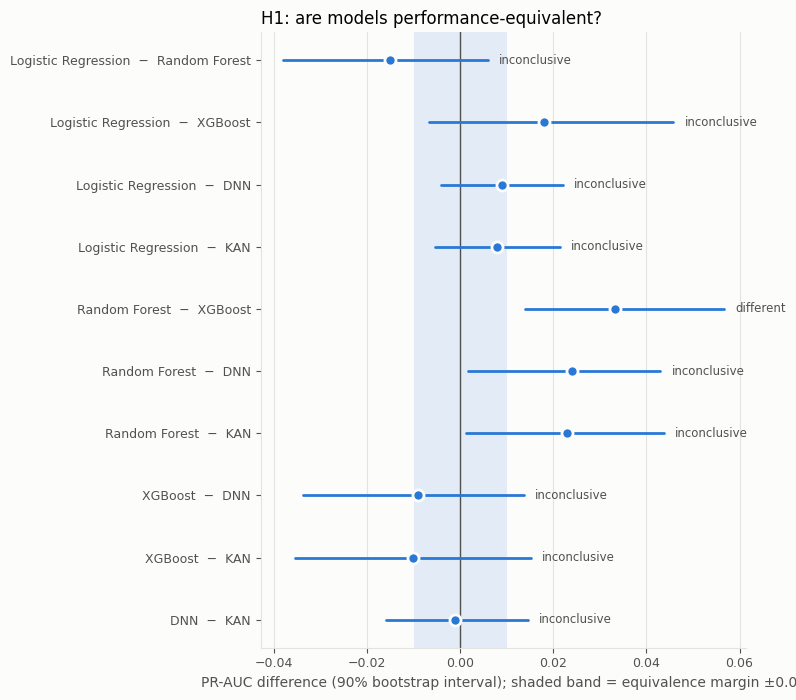

In [8]:
tests = run_hypothesis_tests(grid, cfg, verbose=False)
display(tests["h1"].round(4))

from src.visualization import plot_equivalence_forest
plot_equivalence_forest(tests["h1"]); plt.show()

### 5. H2 and H3 - explanations
H2 asks whether two models' explanations (top-k membership and ranking) differ more than the same model's explanations differ across seeds. H3 flags pairs that are performance-equivalent but explained differently.

,Model_A,Model_B,kind,d_cross,d_within,theta,ci90_low,ci90_high,p_value,p_holm,Supported
0,Logistic Regression,Random Forest,membership,0.4159,0.3492,0.0667,-0.1250,0.2262,0.2881,1.0000,False
1,Logistic Regression,Random Forest,ranking,0.4230,0.2213,0.2017,0.1104,0.3047,0.0034,0.0339,True
2,Logistic Regression,XGBoost,membership,0.4256,0.4643,-0.0387,-0.1468,0.1262,0.7197,1.0000,False
3,Logistic Regression,XGBoost,ranking,0.4905,0.2404,0.2501,0.1530,0.3694,0.0035,0.0339,True
4,Logistic Regression,DNN,membership,0.3899,0.3492,0.0407,-0.1170,0.1857,0.3860,1.0000,False
5,Logistic Regression,DNN,ranking,0.4573,0.2695,0.1878,0.0902,0.2925,0.0070,0.0339,True
6,Logistic Regression,KAN,membership,0.4368,0.4722,-0.0355,-0.1369,0.0814,0.7079,1.0000,False
7,Logistic Regression,KAN,ranking,0.3895,0.2623,0.1273,0.0671,0.1877,0.0103,0.0339,True
8,Random Forest,XGBoost,membership,0.2679,0.2817,-0.0139,-0.1083,0.1071,0.5952,1.0000,False
9,Random Forest,XGBoost,ranking,0.2241,0.1968,0.0273,-0.0364,0.0945,0.3322,0.6644,False


,Model_A,Model_B,H1_equivalent,H2_membership,H2_ranking,H3_supported
0,Logistic Regression,Random Forest,False,False,True,False
1,Logistic Regression,XGBoost,False,False,True,False
2,Logistic Regression,DNN,False,False,True,False
3,Logistic Regression,KAN,False,False,True,False
4,Random Forest,XGBoost,False,False,False,False
5,Random Forest,DNN,False,False,True,False
6,Random Forest,KAN,False,False,True,False
7,XGBoost,DNN,False,False,True,False
8,XGBoost,KAN,False,False,True,False
9,DNN,KAN,False,False,False,False


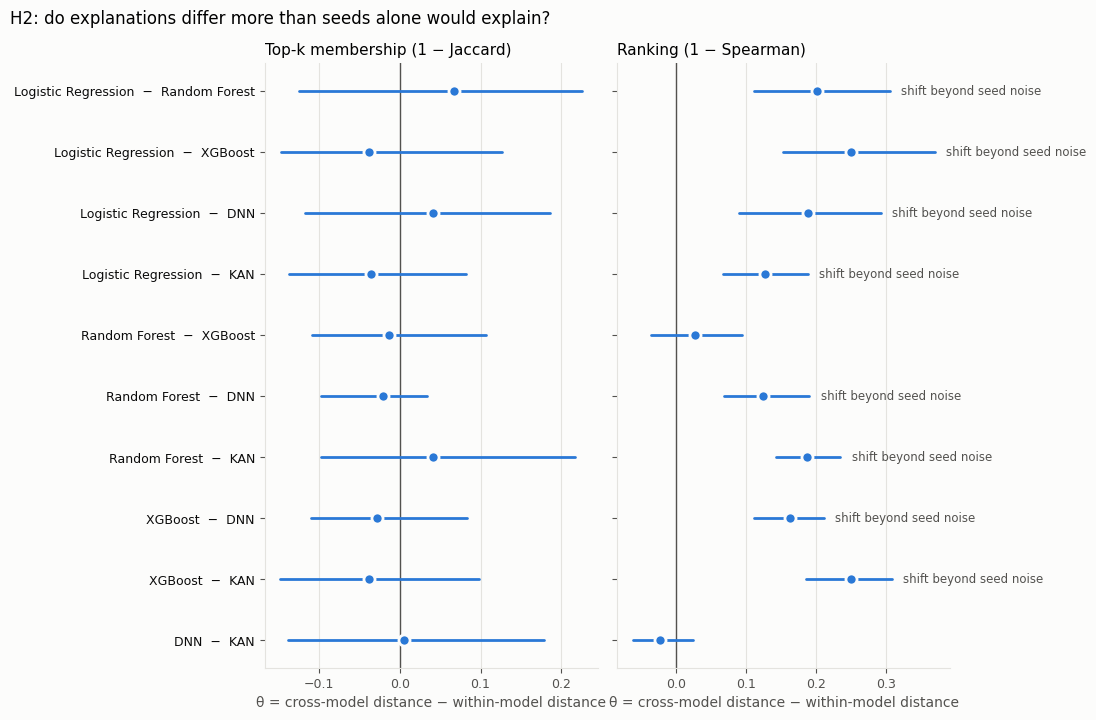

In [10]:
display(tests["h2"].round(4))
display(tests["h3"])

from src.visualization import plot_explanation_shift
plot_explanation_shift(tests["h2"]); plt.show()

### 6. Calibration
Compares Brier score and ECE before and after isotonic recalibration, and draws the reliability curves (closer to the diagonal is better).

,Model,Method,ROC_AUC,Brier,ECE
0,Logistic Regression,none,0.6553,0.1361,0.0283
1,Logistic Regression,isotonic,0.6491,0.1373,0.0298
2,Random Forest,none,0.6532,0.1358,0.0226
3,Random Forest,isotonic,0.6512,0.1360,0.0298
4,XGBoost,none,0.6196,0.1420,0.0594
5,XGBoost,isotonic,0.6318,0.1387,0.0317
6,DNN,none,0.6585,0.1364,0.0298
7,DNN,isotonic,0.6472,0.1377,0.0315
8,KAN,none,0.6441,0.1367,0.0194
9,KAN,isotonic,0.6426,0.1385,0.0311


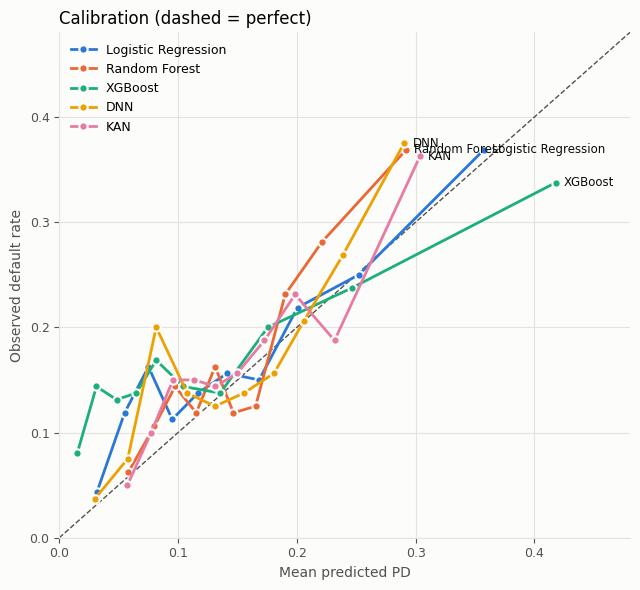

In [11]:
from src.calibration import compare_calibration
from src.visualization import plot_calibration

sub = X_train.sample(min(len(X_train), 20_000), random_state=0)
calib = compare_calibration(grid["fitted"], sub, y_train.loc[sub.index], X_test, y_test, methods=("isotonic",))
display(calib.round(4))
plot_calibration(grid["probs"], grid["y_test"]); plt.show()

### 7. Robustness
PSI measures how far each feature drifted between train and test; the stress table shows mean predicted PD under worse income / DTI / utilisation (it should rise); the backtest trains on earlier years and tests on each later year.

In [12]:
from src.robustness import feature_psi, stress_test

display(feature_psi(X_train, X_test).head(10).round(4))

stress = {}
for name, pipe in grid["fitted"].items():
    stress[name] = stress_test(lambda d, p=pipe: p.predict_proba(d)[:, 1], X_test.head(2_000)) \
        .set_index("Scenario")["Average_PD"]
display(pd.DataFrame(stress).round(4))

,Feature,PSI
0,revol_bal,0.0190
1,total_acc,0.0107
2,earliest_cr_year,0.0084
3,mort_acc,0.0058
4,fico_score,0.0056
5,open_acc,0.0055
6,earliest_cr_month,0.0047
7,emp_length,0.0042
8,revol_util,0.0040
9,pub_rec,0.0036


,Logistic Regression,Random Forest,XGBoost,DNN,KAN
Scenario,,,,,
Baseline,0.1493,0.1497,0.1320,0.1478,0.1531
Moderate stress,0.1698,0.1651,0.1498,0.1626,0.1755
Severe stress,0.1910,0.1787,0.1664,0.1763,0.1971


In [13]:
from src.robustness import chronological_backtest
from src.models import make_pipeline
from src.preprocessing import prepare_frame

# The backtest needs the dated frame (the split above removed the dates), so rebuild it.
frame = prepare_frame(raw, sample_size=None if USE_SYNTHETIC else cfg.sample_size,
                      max_issue_year=cfg.max_issue_year, drop_lender_assigned=cfg.drop_lender_assigned)
bt = chronological_backtest(lambda X, y: make_pipeline("Logistic Regression", X), frame,
                            first_test_year=2014, min_train=500 if USE_SYNTHETIC else 3_000,
                            min_test=200 if USE_SYNTHETIC else 500)
display(bt.round(4))

,Test_Year,Observations,Observed_Default_Rate,Average_Predicted_PD,ROC_AUC,PR_AUC,Brier
0,2014,1524,0.1496,0.1308,0.6712,0.2650,0.1216
1,2015,1462,0.1594,0.1413,0.6782,0.2795,0.1269
2,2016,1478,0.1691,0.1448,0.6470,0.2726,0.1356


### 8. With vs without the lender's own score
Runs the whole experiment twice - without and with `int_rate` / `sub_grade` - to show how much of each model's performance is just LendingClub's own underwriting score.

In [ ]:
if COMPARE_FEATURE_SETS:
    both = run_feature_set_comparison(cfg, synthetic=USE_SYNTHETIC, verbose=False)
    display(both["comparison"][["roc_auc", "pr_auc", "brier", "ece", "explanation_stability"]].round(4))
else:
    print("Skipped (COMPARE_FEATURE_SETS = False).")

### 9. Scorecard and trade-offs
Turns the measured results into relative 0-100 scores per model (radar chart), plots performance against complexity, and lists Pareto-dominated models. Keep the raw tables above next to these scores: they only rank the compared models against each other.

,Performance,Calibration,Generalization,Efficiency,Robustness,Explanation_Stability
Model,,,,,,
Logistic Regression,72.5,87.3,100.0,99.9,100.0,9.4
Random Forest,100.0,100.0,40.0,23.8,93.2,100.0
XGBoost,0.0,0.0,0.0,57.2,0.0,60.4
DNN,55.1,84.7,95.2,34.2,38.7,0.0
KAN,45.6,84.8,95.9,29.7,75.0,15.0


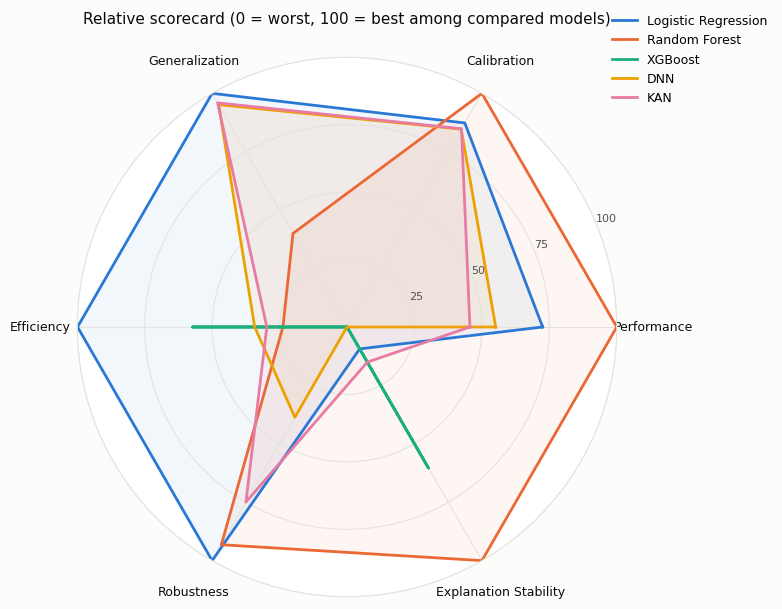

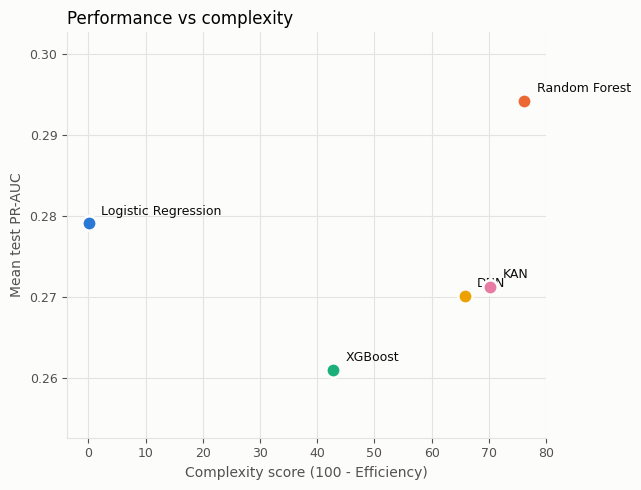

{'Logistic Regression': [], 'Random Forest': [], 'XGBoost': [], 'DNN': ['Logistic Regression'], 'KAN': []}


In [14]:
from src.scoring import build_scorecard, complexity_score, find_dominated_models
from src.visualization import plot_radar, plot_tradeoff

scorecard = build_scorecard(summary, grid["complexity"])
display(scorecard.round(1))
plot_radar(scorecard); plt.show()

table = summary.join(scorecard)
table["Complexity_Score"] = complexity_score(scorecard)
plot_tradeoff(table, "Complexity_Score", "pr_auc", "Complexity score (100 - Efficiency)",
              "Mean test PR-AUC", "Performance vs complexity", min_y_span=0.05); plt.show()

print(find_dominated_models(table, maximize=["pr_auc", "explanation_stability"], minimize=["Complexity_Score"]))
save_tables(cfg.output_dir, grid, tests, summary, scorecard)

### 10. Robustness and the full figure set
Runs drift (PSI), sensitivity, stress and the chronological backtest, then draws every remaining figure (ROC, confusion matrices, threshold trade-off, importance bars, seed boxplots, rank agreement, robustness charts, trade-off dashboard) and saves them to `outputs/figures/`. Sensitivity and stress shocks are illustrative, not macro-calibrated.

Features where a one-at-a-time ranking and the model explanation disagree most:


,Model,Feature,Spearman_with_default,Univariate_rank,Model_importance,Model_rank,Rank_gap
54,Random Forest,pub_rec_bankruptcies,-0.011,7.0,0.005,16.0,-9.0
62,Random Forest,revol_bal,0.001,15.0,0.028,6.0,9.0
78,XGBoost,revol_bal,0.001,15.0,0.055,6.0,9.0
70,XGBoost,pub_rec_bankruptcies,-0.011,7.0,0.008,16.0,-9.0
69,XGBoost,emp_length,0.015,6.0,0.025,14.0,-8.0
53,Random Forest,emp_length,0.015,6.0,0.014,13.0,-7.0
9,DNN,installment,-0.004,10.0,0.016,16.0,-6.0
27,KAN,loan_amnt,0.003,12.0,0.029,6.0,6.0


Wrote 19 figures to outputs/figures/


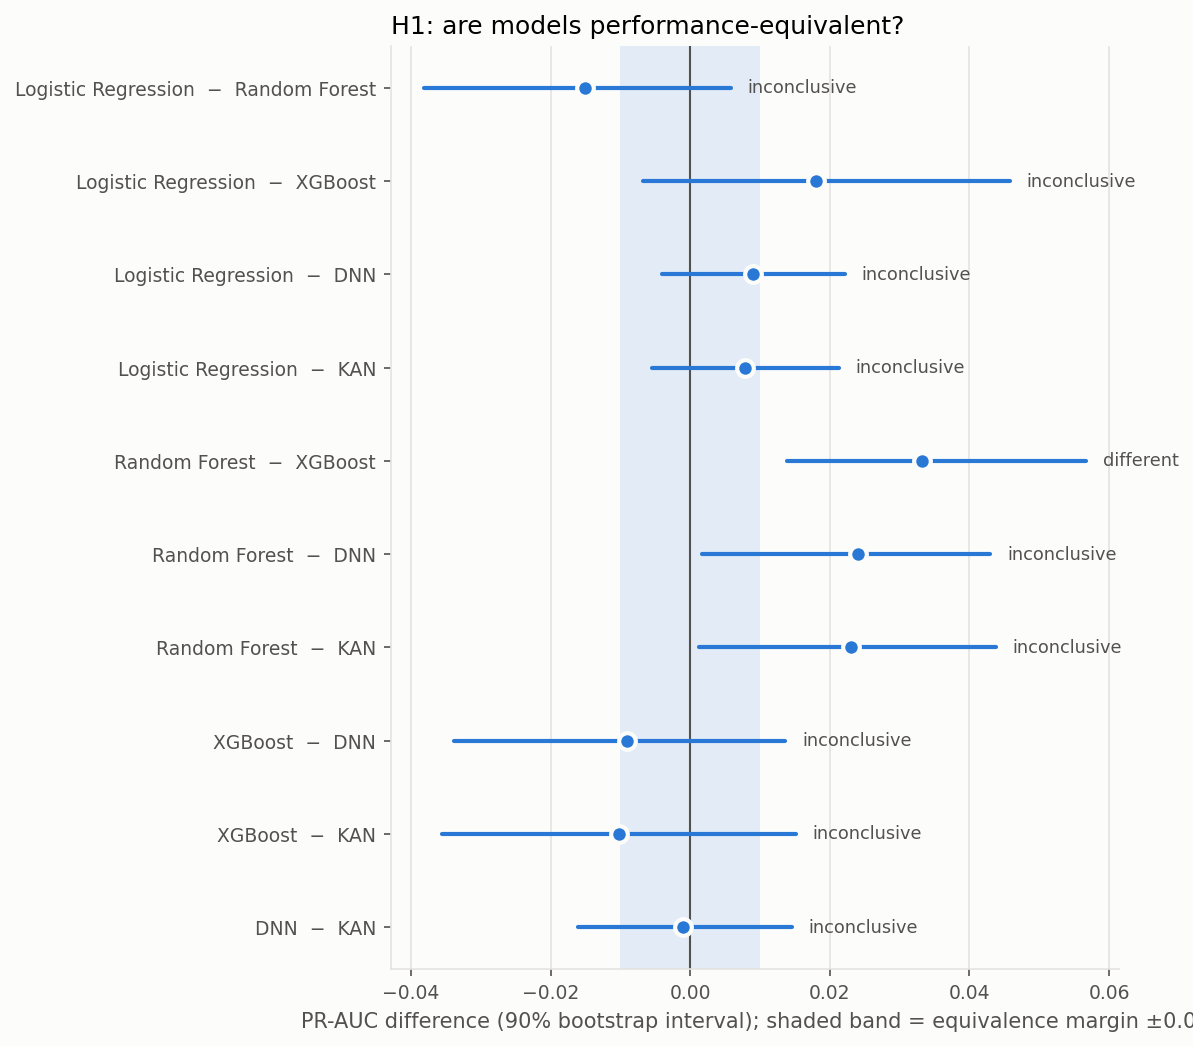

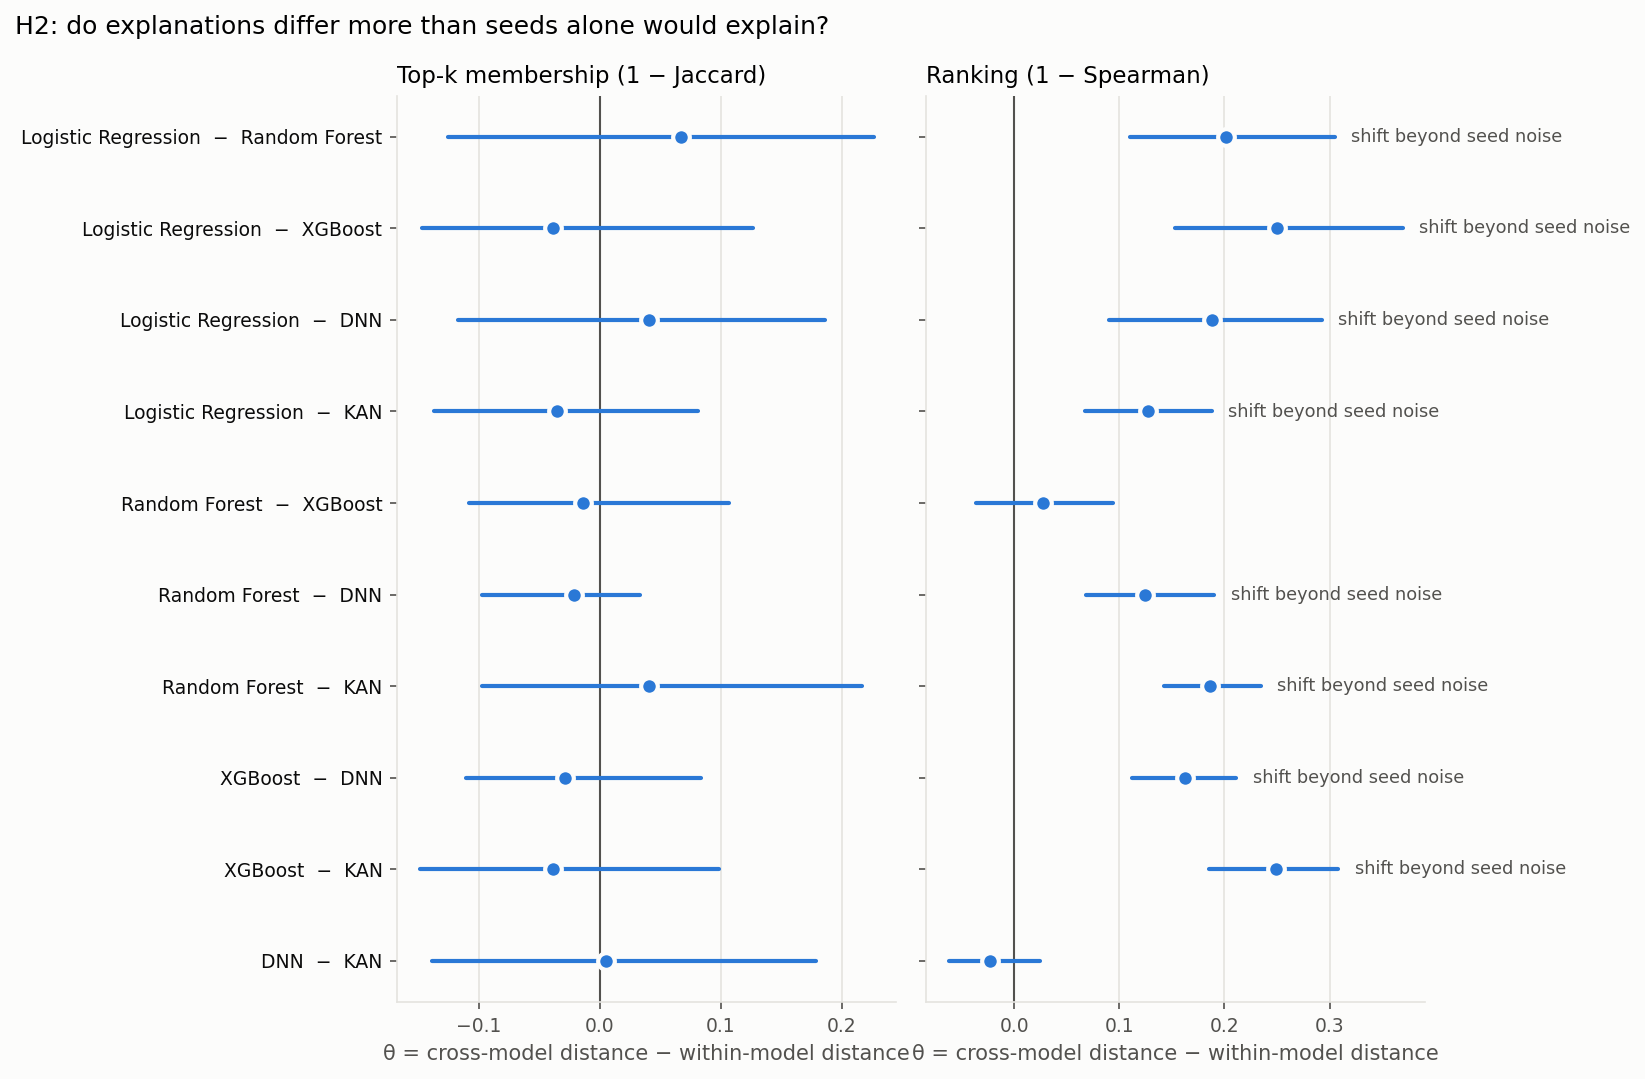

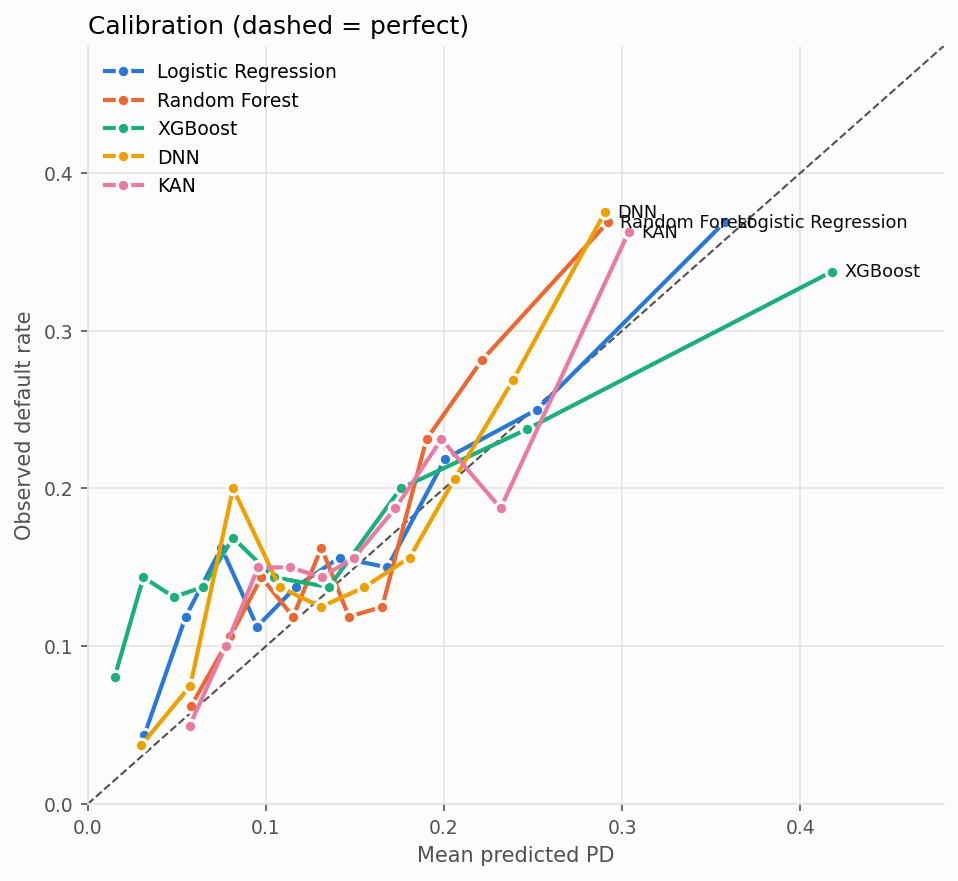

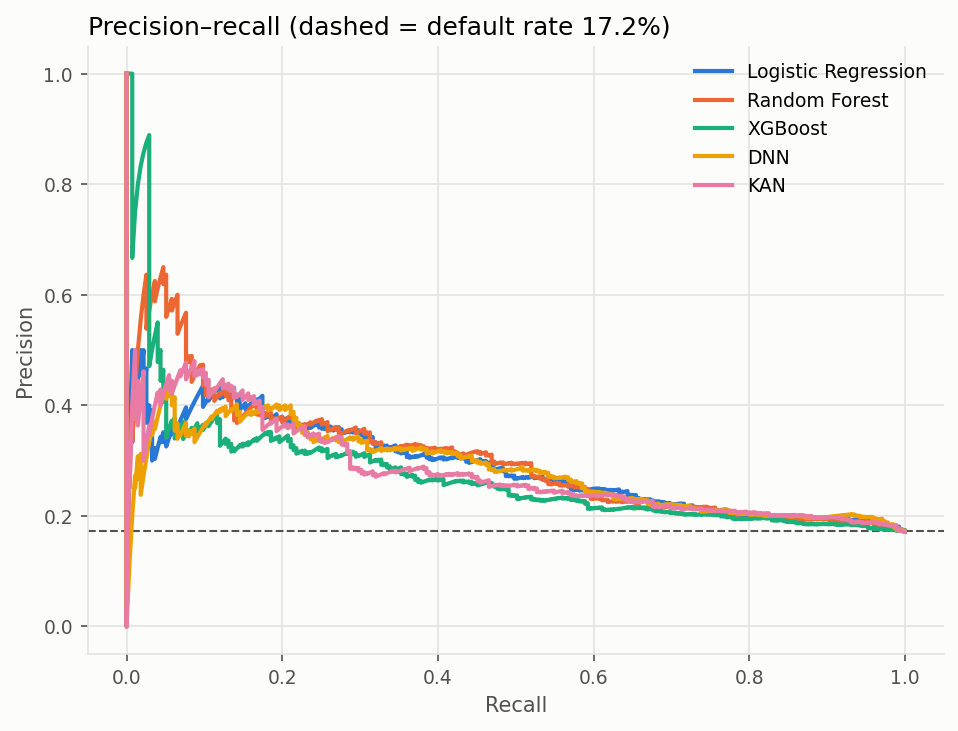

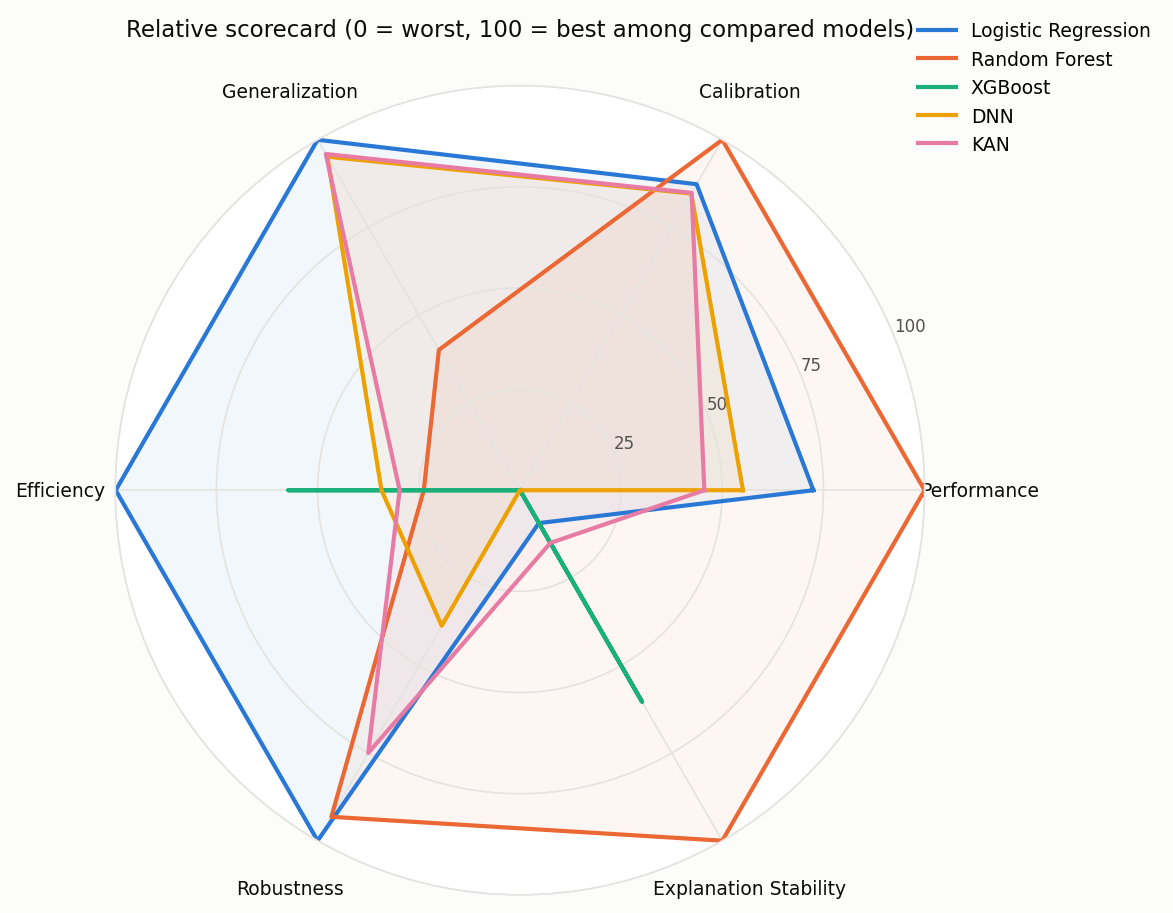

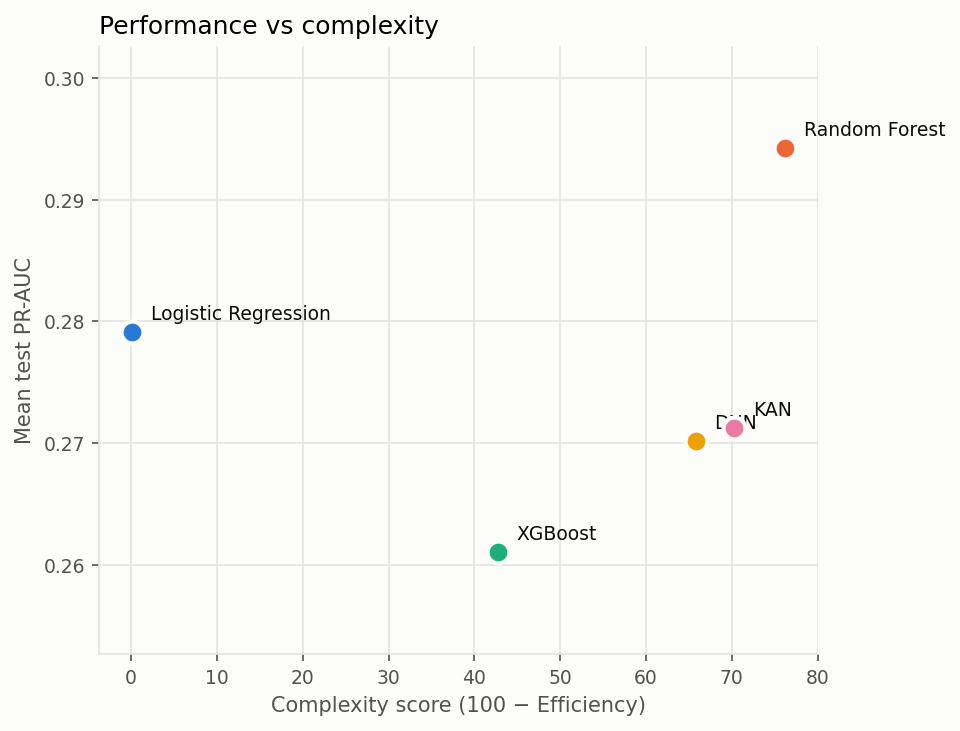

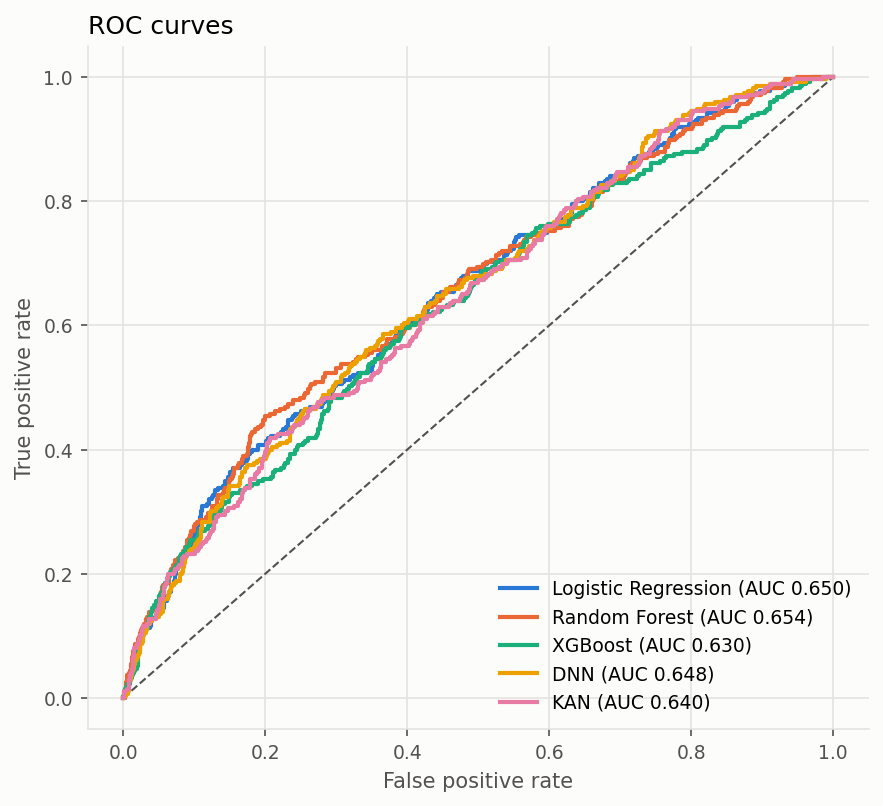

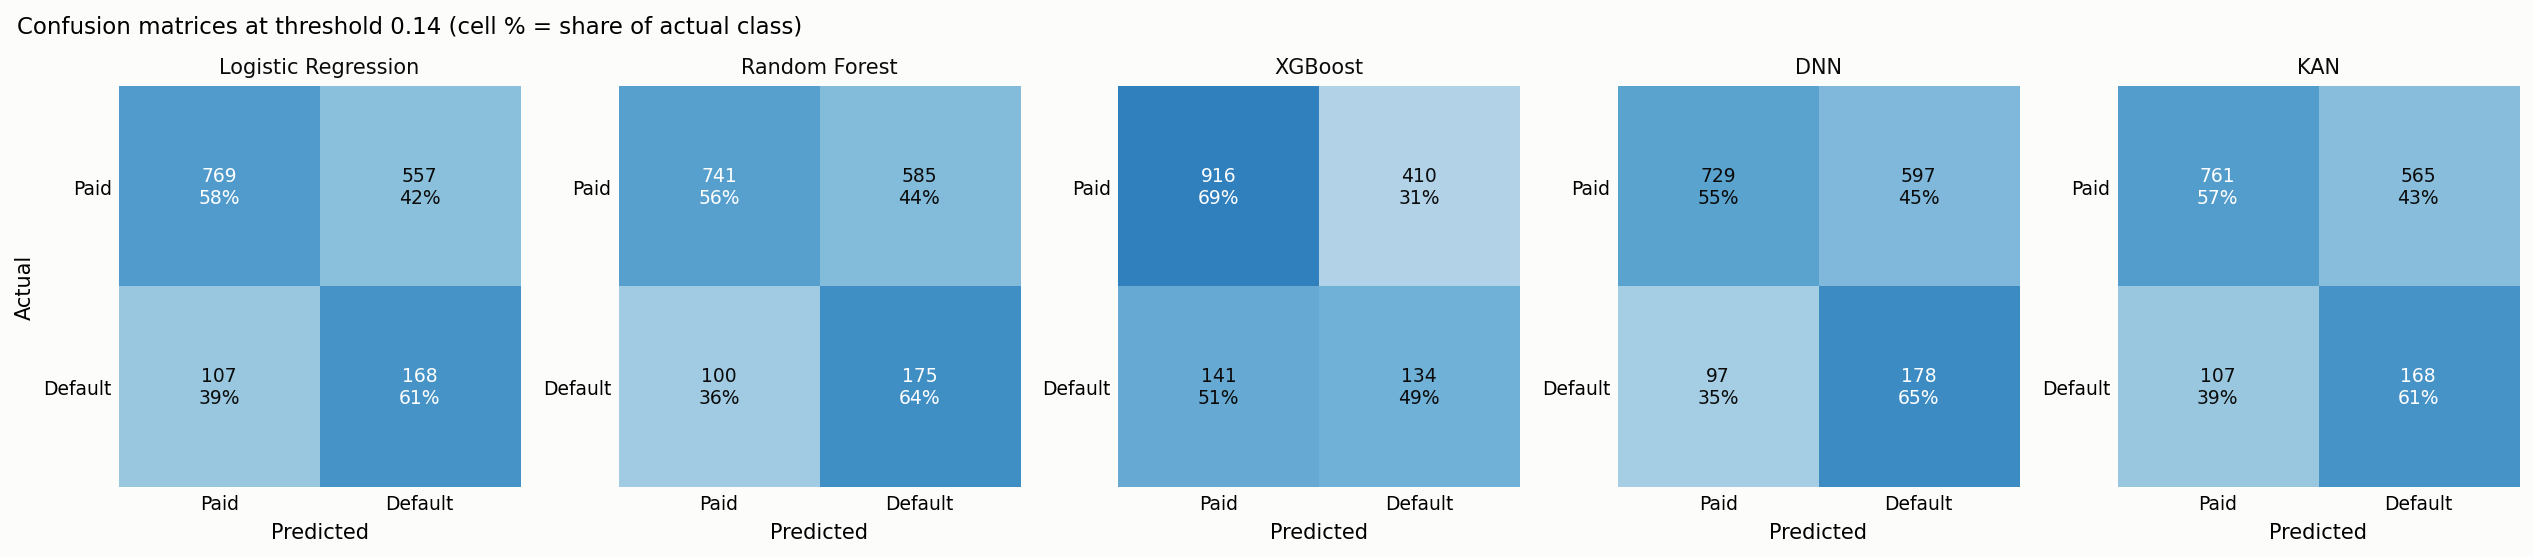

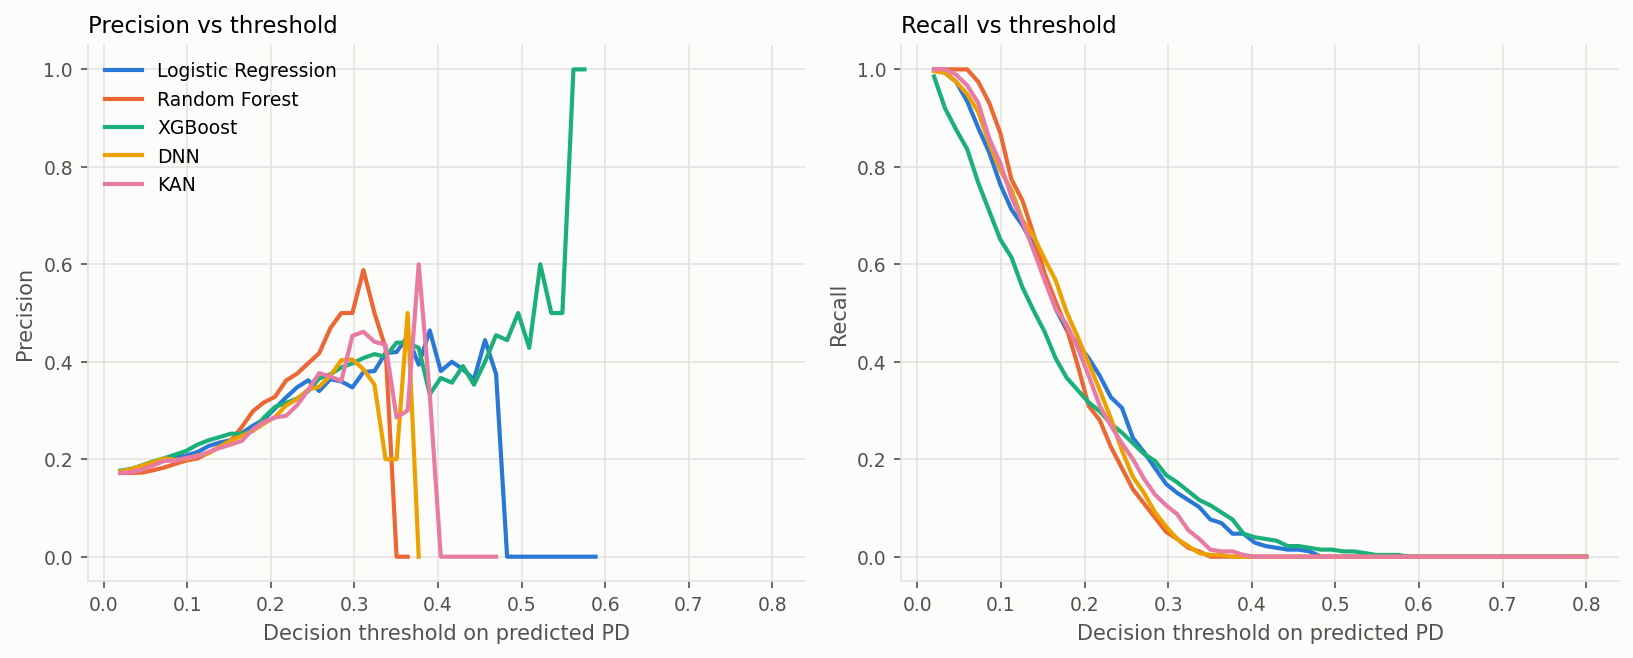

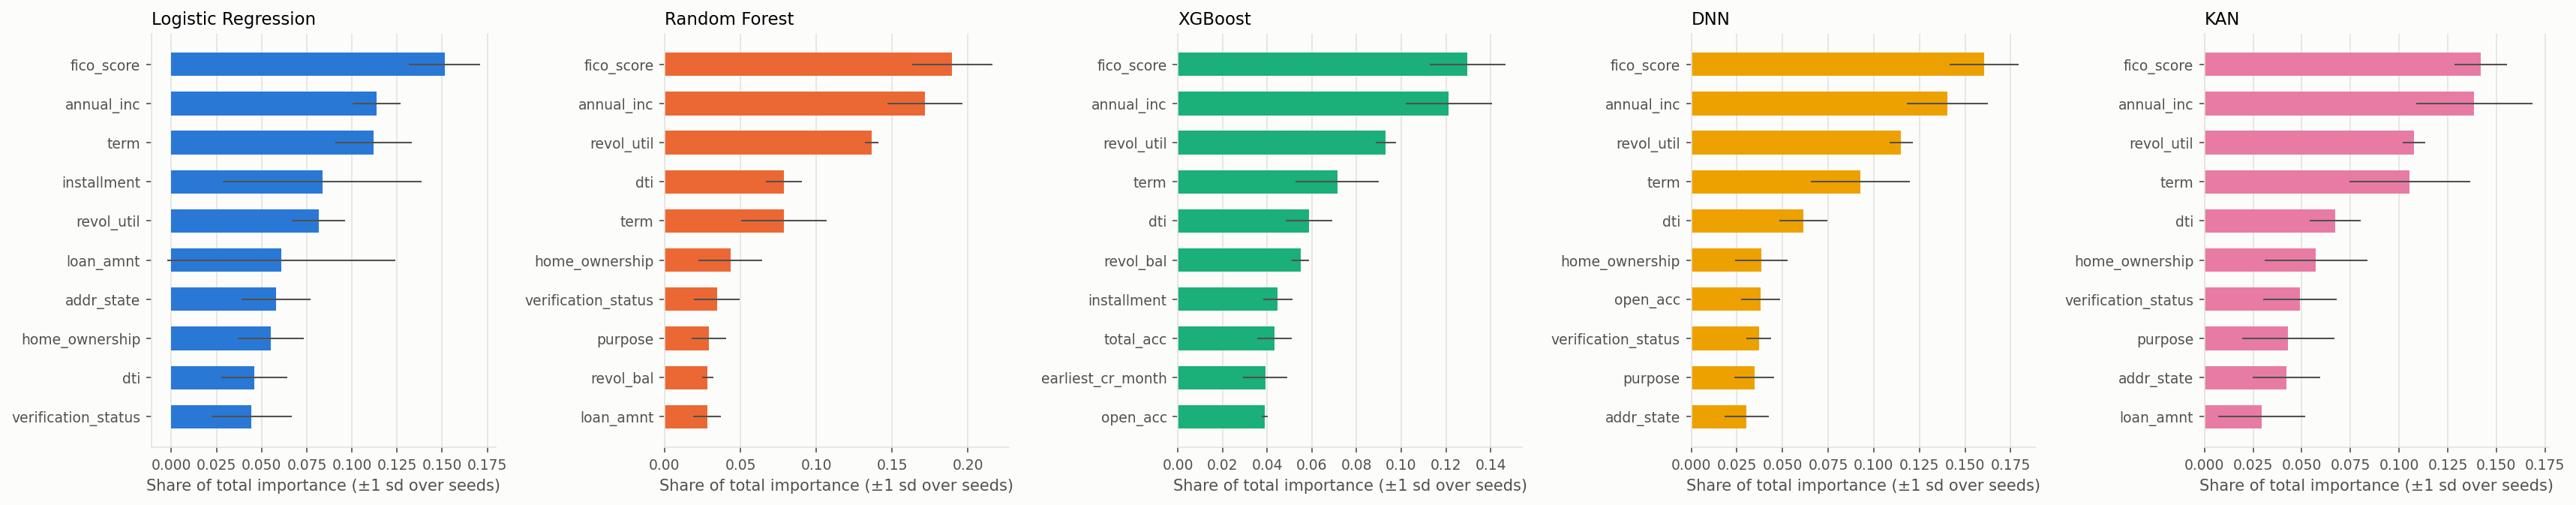

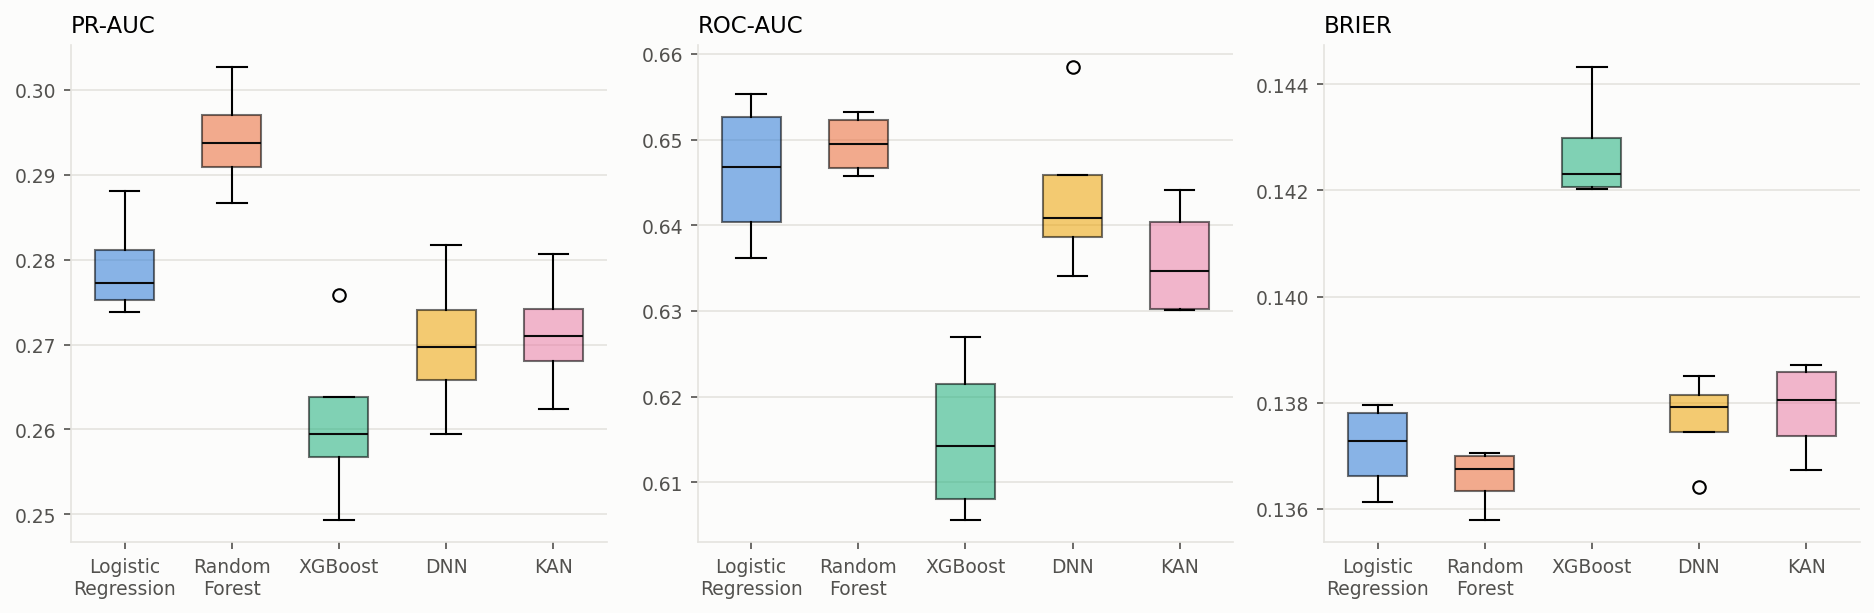

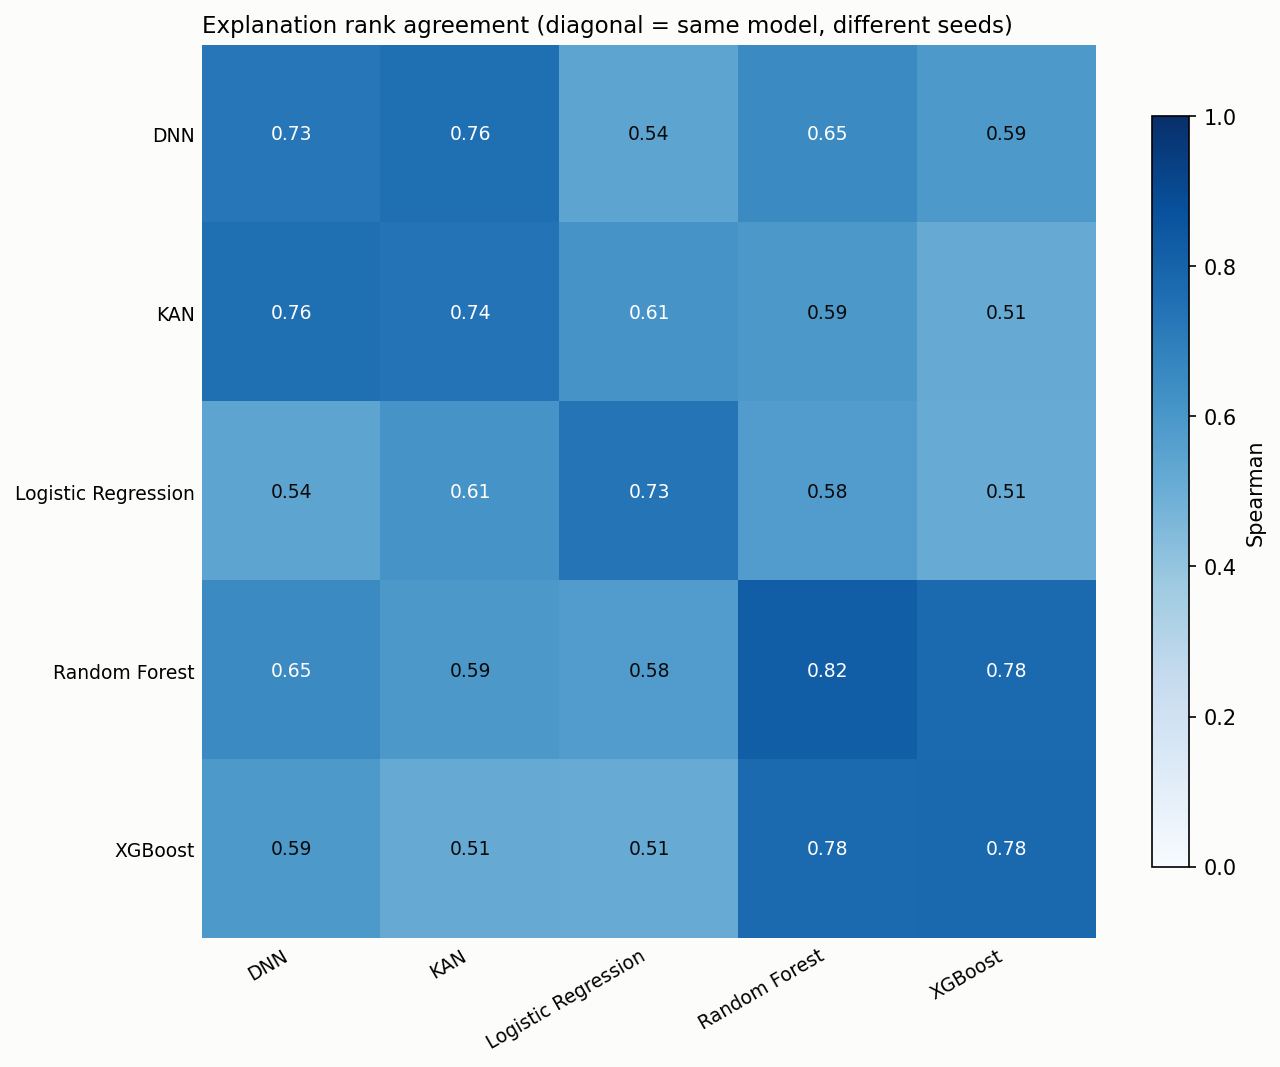

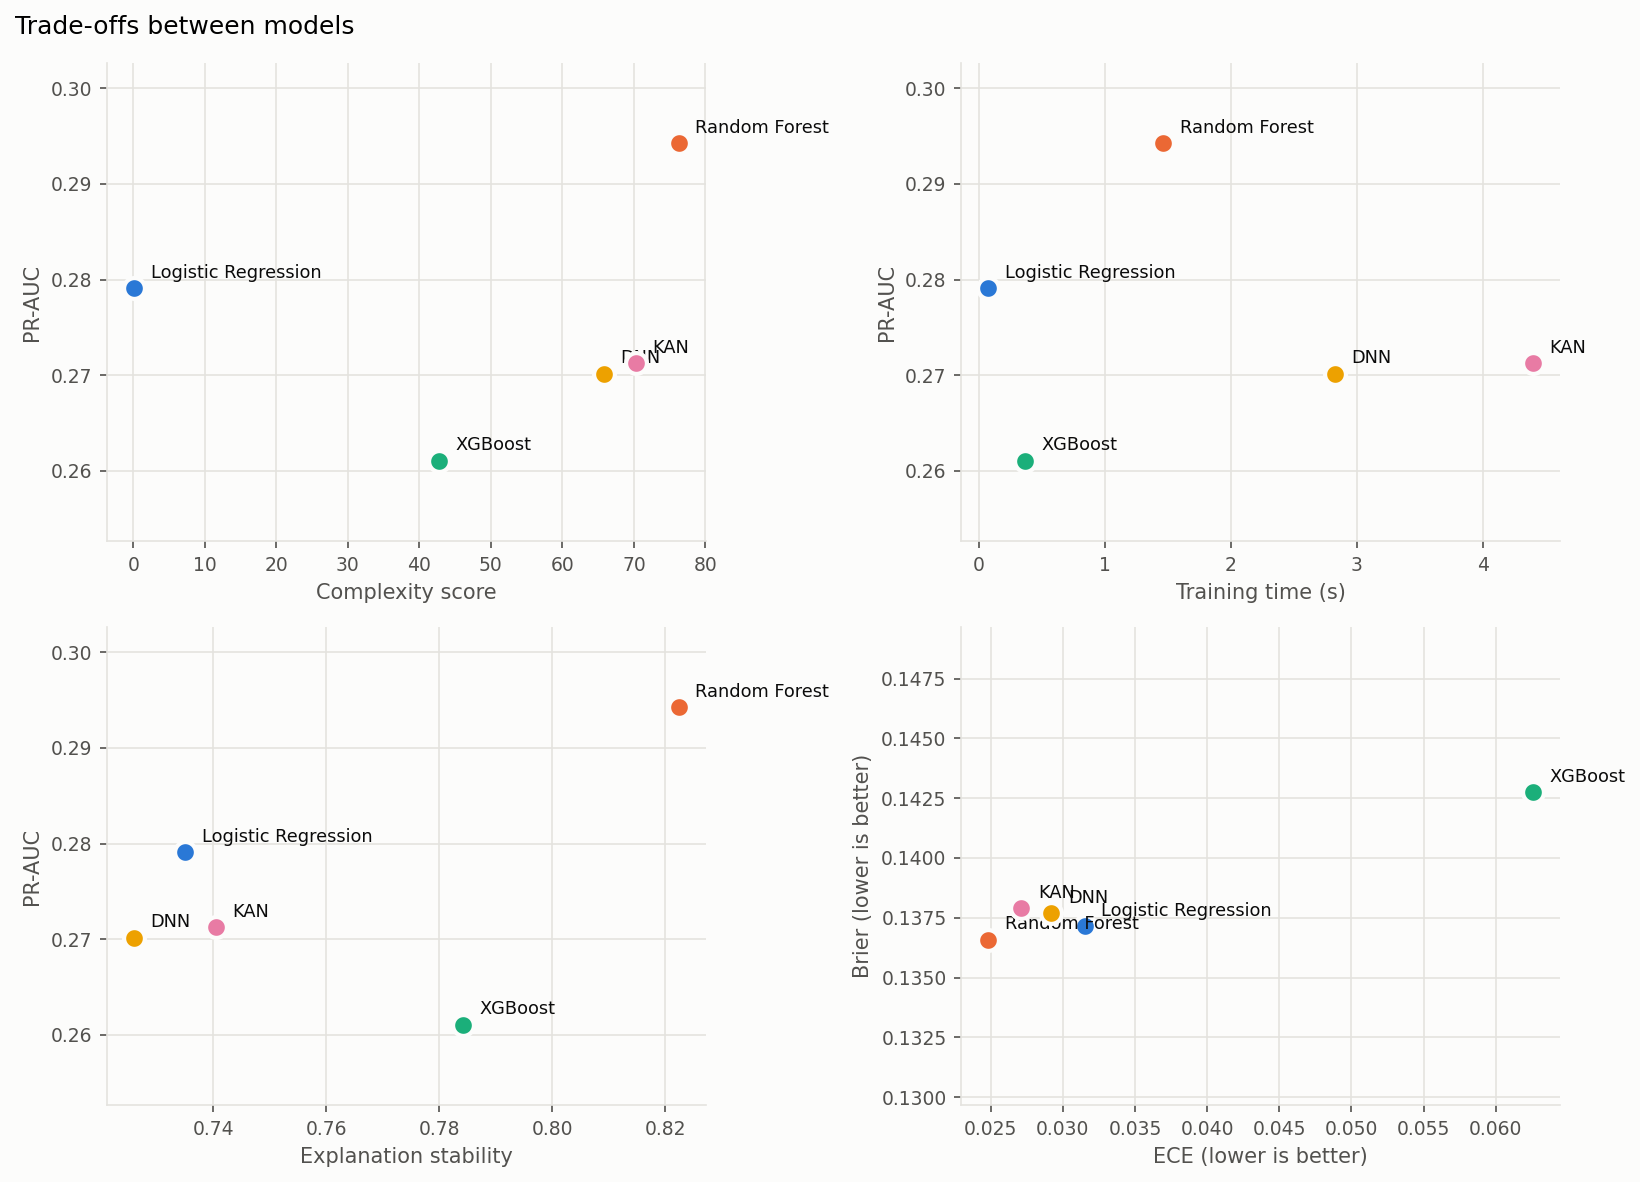

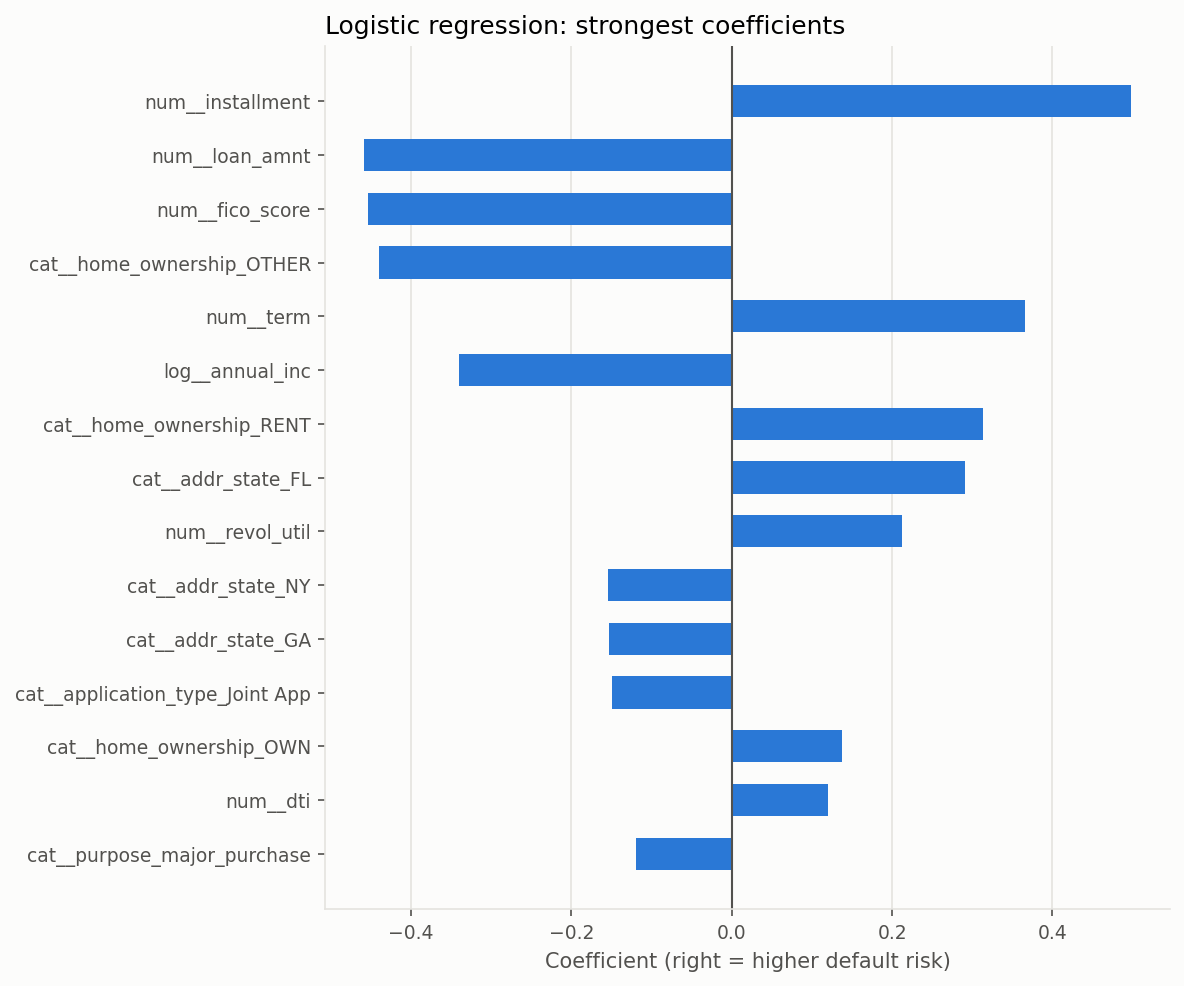

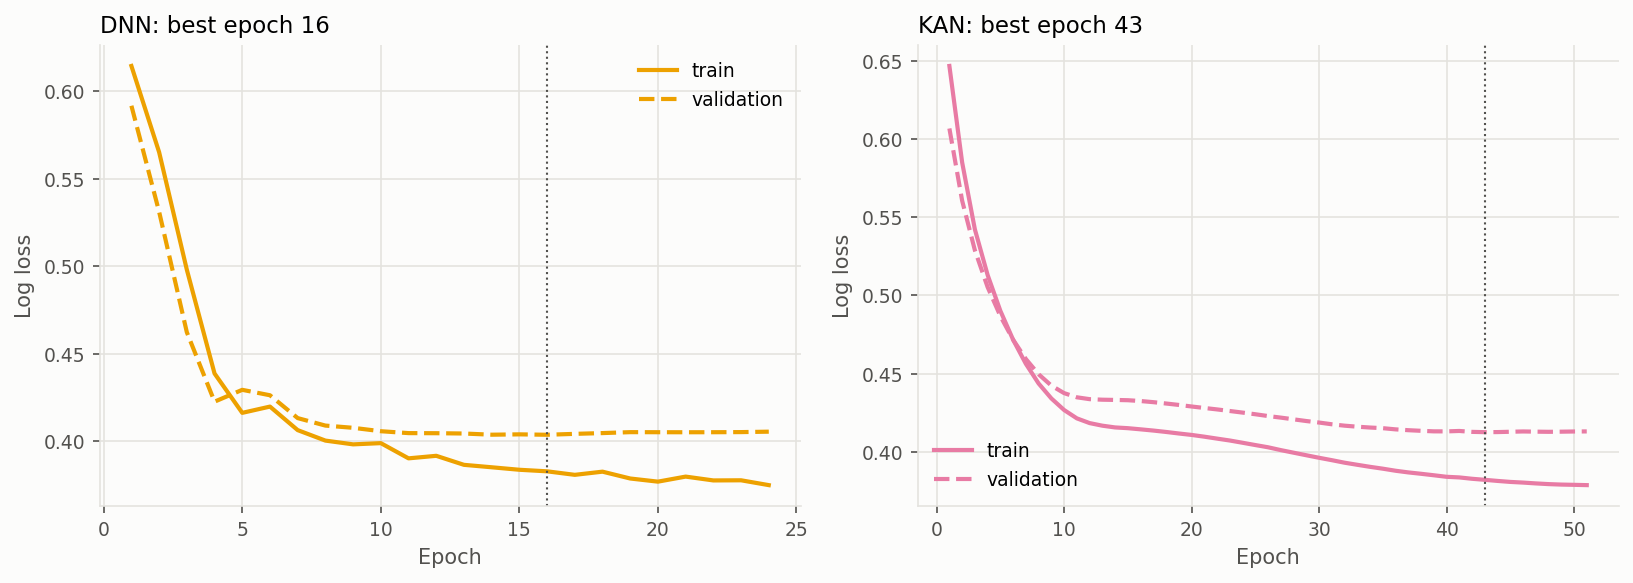

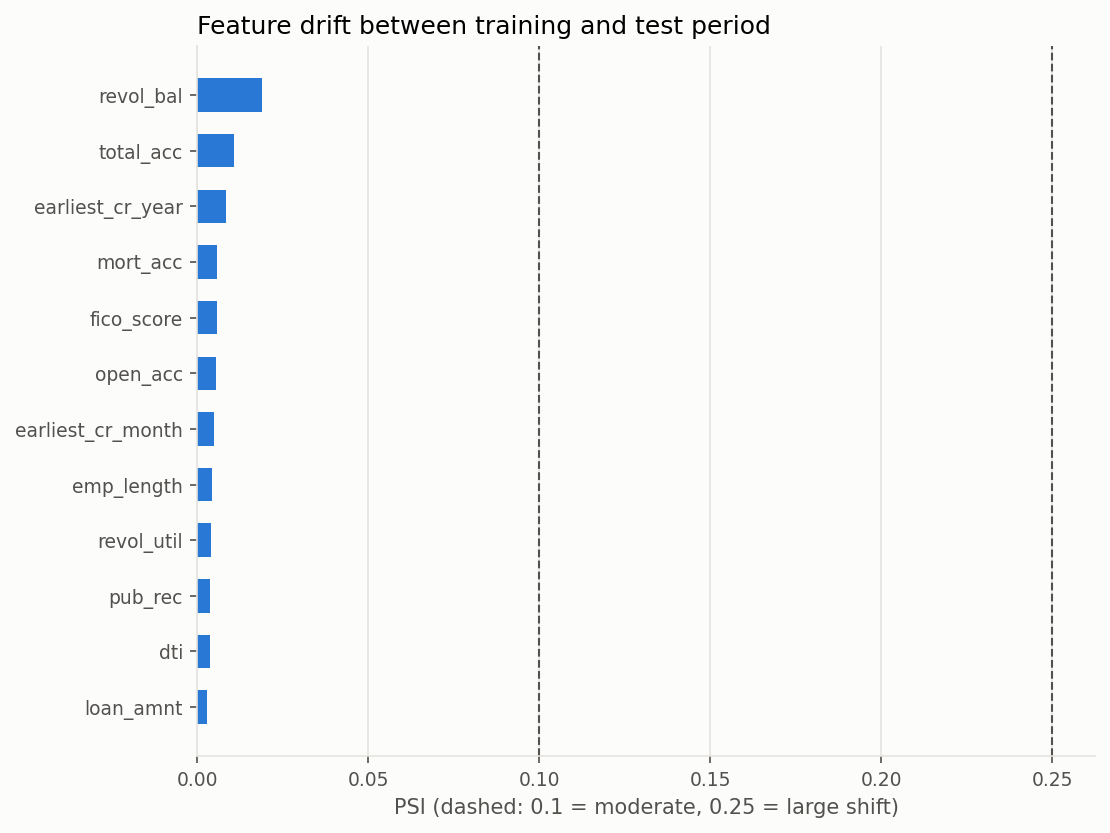

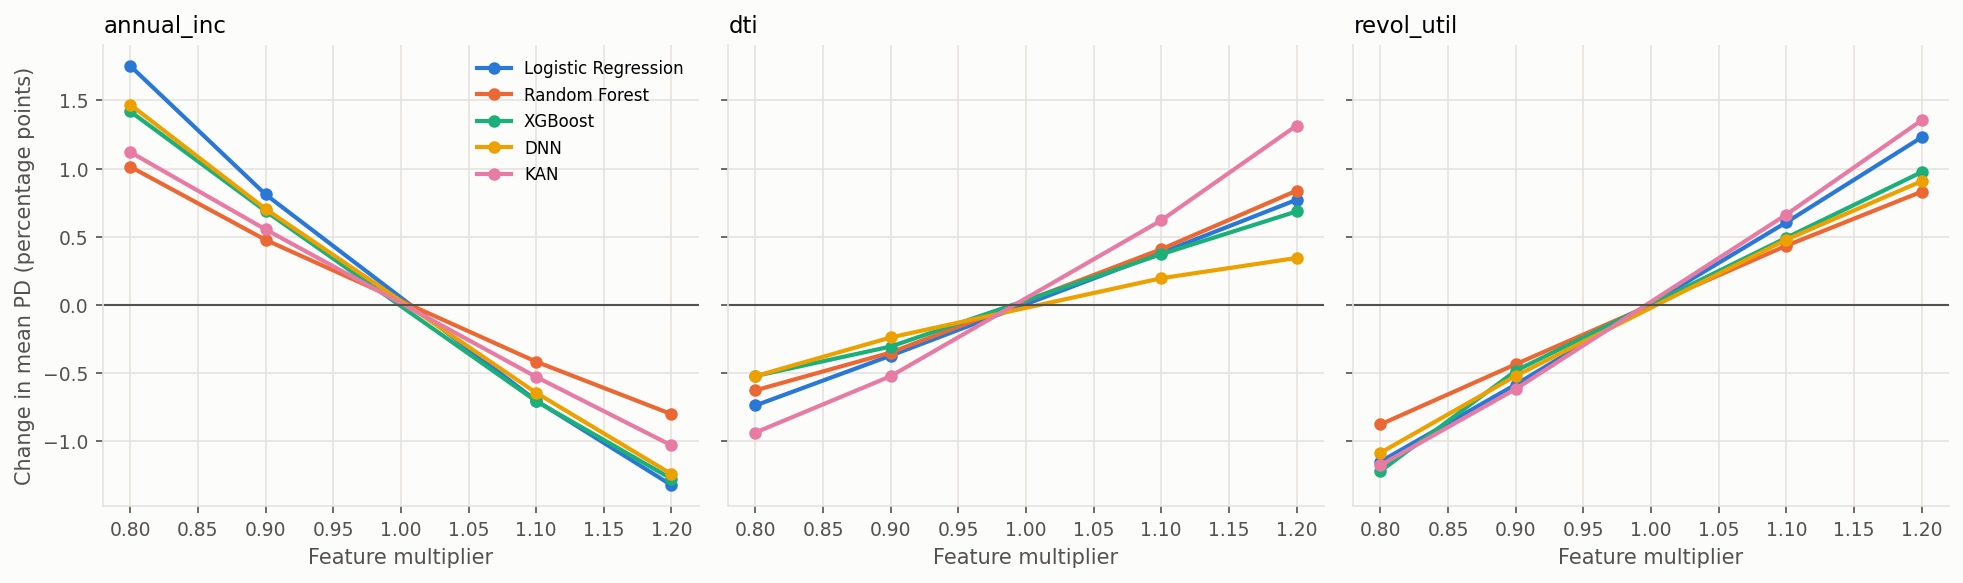

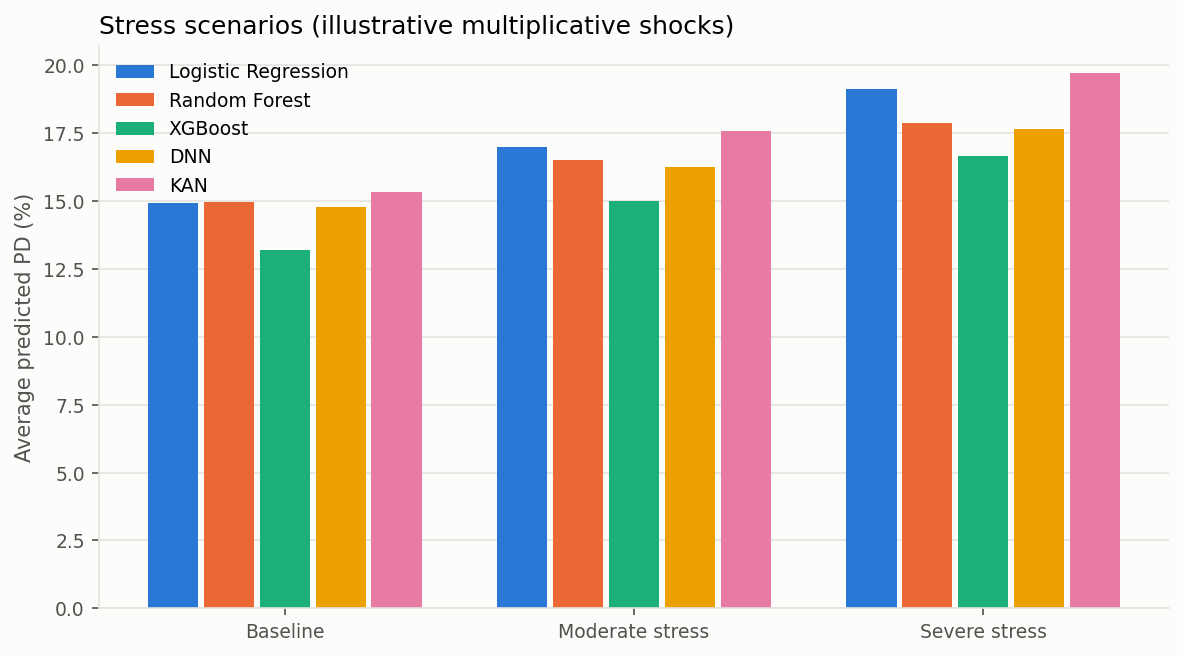

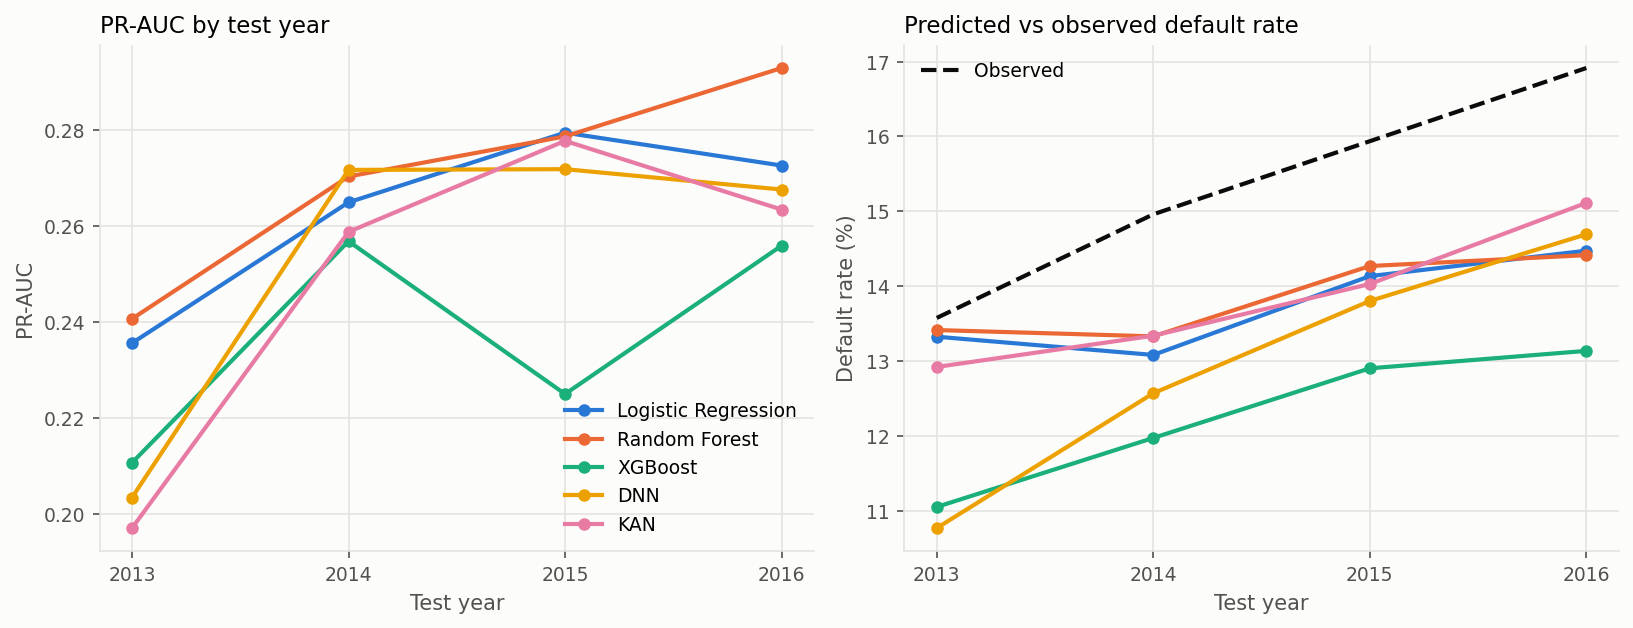

In [15]:
from src.experiments import run_robustness
from src.visualization import save_all

frame = load_frame(cfg, USE_SYNTHETIC)
cfg_fig = replace(cfg, backtest_first_year=2013, backtest_min_train=500, backtest_min_test=100) if USE_SYNTHETIC else cfg
robustness = run_robustness(grid, splits, frame, cfg_fig, verbose=False)
result = {"grid": grid, "tests": tests, "summary": summary, "scorecard": scorecard, "robustness": robustness}
from src.eda import numeric_default_correlation, univariate_vs_explanation
gap = univariate_vs_explanation(numeric_default_correlation(frame), grid["importances"])
print("Features where a one-at-a-time ranking and the model explanation disagree most:")
display(gap.reindex(gap["Rank_gap"].abs().sort_values(ascending=False).index).head(8).round(3))
paths = save_all(result, ROOT / "outputs" / "figures")
print(f"Wrote {len(paths)} figures to outputs/figures/")
from IPython.display import Image, display as _d
for p in paths:
    _d(Image(filename=str(p), width=800))

### Reading the results

- An *inconclusive* H1 verdict means the data cannot show equivalence **or** a difference; it is not evidence of "no difference".
- H3 is only meaningful when H1 says *equivalent* and H2 survives Holm correction.
- SHAP explains model behaviour, not causes. The scorecard is relative: keep the raw tables next to it.